# MODEL PIPELINE - Data Type Profiler
1. Load libraries
2. Setup training pipelines for Tree and Neural Network models
3. Load data
4. Initialize models
5. Train models
6. Compare results

---
**Revision notes (changes relative to the originally released notebook)**
1. **Input standardization for the neural networks** (new section 3.1). Features are z-scored with a `StandardScaler` fitted on the training split only. Tree models keep raw features (scale-invariant). Set `USE_SCALING = False` to reproduce the original, unscaled NN results.
2. **Seeding:** the model is now constructed *after* seeding, so weight initialisation is reproducible.
3. **Sub-network fixes:** `StatsNeuralNetwork` / `ColNameNeuralNetwork` previously applied softmax inside `forward()` *and* then `CrossEntropyLoss` (double softmax); they now return logits. The invalid `dropout_rate` argument was removed.
4. **New section 8:** robustness over random seeds (RF, NN and the RF+NN ensemble), reported as mean ± std.
5. **Sections 9–14 (new):** extended evaluation — seed variance, grouped splits, scaled-vs-unscaled NN, ablations, PCA size — all in this notebook. Results are cached in `results/*.json` and loaded by default; set `RUN_EXPERIMENTS = True` in section 9 to recompute them (≈40 min on one CPU).
6. **Multiple seeds everywhere (this revision).** Every headline number in sections 5–7 is now mean ± std over `SEEDS`; the NN grid search picks the configuration with the best *mean* validation G-mean; the RF+NN alpha is re-tuned on validation for every seed; confusion matrices are summed over seeds. Fixed a bug where `nn_model_training_pipeline` re-seeded with the global `SEED`, so §8's NN "seeds" differed only in weight init (batch order and dropout were identical).
7. **Grouped split (this revision).** `SPLIT_NAME` (section 3) selects the split written by `04_data_preparation.ipynb`; the default `table_seed42` keeps every source table in a single partition, so test tables are unseen in training. `"paper"` loads the original column-level random split from `data/`.
8. Sections 9–14 use the split from section 3 and the NN learning rate / batch size selected in §5.4 (previously hard-coded to 0.005 / 512), cache results per split and hyper-parameters under `results/<split>_lr…_bs…/`, and §11 trains several model seeds on every split.

## 1. Load Libraries

In [1]:
import os; os.makedirs('figures', exist_ok=True)
import io, contextlib
import time
import random
import numpy as np
import pandas as pd
from itertools import product
from collections import Counter
import seaborn as sns
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from imblearn.metrics import geometric_mean_score

from model.tree_model import TreeModel
from model.modular_neural_network_model import ModularNeuralNetwork
from model.stats_neural_network import StatsNeuralNetwork
from model.col_name_neural_network import ColNameNeuralNetwork

In [2]:
import pandas as pd

print(pd.__version__)
print(pd.__file__)

2.3.3
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pandas/__init__.py


## 2. Training Pipelines

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

SEED  = 42                 # reference seed: single-run outputs (feature importance, training curves)
SEEDS = [42, 0, 1, 2, 3]   # headline numbers are mean ± std over these seeds (more seeds = tighter estimate, slower)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

Using device: cpu


### 2.1 Tree Model Pipeline

In [4]:
def tree_model_training_pipeline(X_train, y_train, X_val, y_val, X_test, y_test, model, X_test_column):
    start_time = time.time()

    model.train(X_train, y_train)
    model.evaluate(X_train, y_train, X_val, y_val, X_test, y_test, X_test_column)

    training_time = time.time() - start_time

    print(f"Training completed in {training_time:.2f} seconds")
    print(f"Train Accuracy      : {model.metrics['train_accuracy']:.2f}%")
    print(f"Validation Accuracy : {model.metrics['validation_accuracy']:.2f}%")
    print(f"Validation G-Mean   : {model.metrics['validation_gmean']:.4f}")

### 2.2 Neural Network Pipeline

In [5]:
def nn_model_training_pipeline(X_train, y_train, X_val, y_val, X_test, y_test, X_test_column, model,
                                epochs=50, batch_size=32, lr=0.001, weight_decay=1e-3,
                                patience=10, min_delta=0.001, monitor="val_gmean", seed=SEED):
    start_time = time.time()
    set_seed(seed)   # the run's own seed (previously always the global SEED) -> batch order and dropout vary per seed

    model.prep_data_loader(X_train, y_train, X_val, y_val, X_test, y_test, batch_size)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    model.train_epochs(optimizer, scheduler, epochs, device, patience, min_delta, monitor)
    model.evaluate(X_test_column, device)

    training_time = time.time() - start_time
    print(f"\nTraining completed in {training_time:.2f} seconds")
    print(f"Best Validation {monitor}: {model.metrics['best_val_metric']:.4f}")

    return model


def nn_probs(model, loader):
    """Softmax probabilities of the best checkpoint, in loader order (val/test loaders are not shuffled)."""
    model.load_state_dict(model.best_model_state); model.eval(); out = []
    with torch.no_grad():
        for batch in loader:
            inputs = [t.to(device) for t in batch[:-1]]
            out.append(torch.softmax(model(*inputs), dim=1).cpu().numpy())
    return np.vstack(out)


METRIC_KEYS = ['test_accuracy', 'test_precision', 'test_recall', 'test_f1score', 'test_gmean', 'confusion_matrix']

def classification_metrics(y_true, y_pred):
    """Same definitions as TreeModel.evaluate / BaseNeuralNetworkModel.evaluate."""
    y_true = np.asarray(y_true).astype(int).ravel(); y_pred = np.asarray(y_pred).astype(int).ravel()
    return {
        'test_accuracy':    accuracy_score(y_true, y_pred) * 100,
        'test_precision':   precision_score(y_true, y_pred, average='weighted', zero_division=0) * 100,
        'test_recall':      recall_score(y_true, y_pred, average='weighted', zero_division=0) * 100,
        'test_f1score':     f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'test_gmean':       geometric_mean_score(y_true, y_pred, average='multiclass'),
        'confusion_matrix': confusion_matrix(y_true, y_pred, labels=list(range(4))),
    }


def mean_std_table(runs, keys=('test_accuracy', 'test_f1score', 'test_gmean')):
    """runs: {model name: [metrics dict per seed]} -> table of 'mean ± std' strings."""
    rows = {}
    for name, L in runs.items():
        d = pd.DataFrame(L)
        row = {'n seeds': len(L)}
        for k in keys:
            dec = 2 if k in ('test_accuracy', 'test_precision', 'test_recall') else 4
            sd = d[k].std(ddof=1) if len(L) > 1 else 0.0
            row[k] = f"{d[k].mean():.{dec}f} ± {sd:.{dec}f}"
        rows[name] = row
    return pd.DataFrame(rows).T

## 3. Load Data

In [6]:
# Which split to use: a folder written by 04_data_preparation.ipynb (data/splits/<SPLIT_NAME>/),
# or "paper" for the original column-level random split in data/.
SPLIT_NAME = "table_seed42"
DATA_DIR = "data/" if SPLIT_NAME == "paper" else f"data/splits/{SPLIT_NAME}/"
print(f"Loading split '{SPLIT_NAME}' from {DATA_DIR}")

LABELENCODER = {
    # integer labels: newer scikit-learn (>= 1.8) rejects class_weight='balanced' with string labels
    'varchar':   0,
    'number':    1,
    'boolean':   2,
    'time':      3,
    'date':      3,
    'timestamp': 3,
}

X_train = pd.read_csv(DATA_DIR + 'X_train.csv')
X_train = X_train.drop(columns=['ColumnName'])
y_train_labels = pd.read_csv(DATA_DIR + 'y_train.csv')
y_train = y_train_labels['DataType'].map(LABELENCODER).to_frame(name="DataType")

X_val = pd.read_csv(DATA_DIR + 'X_val.csv')
X_val = X_val.drop(columns=['ColumnName'])
y_val_labels = pd.read_csv(DATA_DIR + 'y_val.csv')
y_val = y_val_labels['DataType'].map(LABELENCODER).to_frame(name="DataType")

X_test = pd.read_csv(DATA_DIR + 'X_test.csv')
X_test_column = X_test['ColumnName']
X_test = X_test.drop(columns=['ColumnName'])
y_test_labels = pd.read_csv(DATA_DIR + 'y_test.csv')
y_test = y_test_labels['DataType'].map(LABELENCODER).to_frame(name="DataType")

feature_cols = X_train.columns
print(f"train {len(X_train)} | val {len(X_val)} | test {len(X_test)} columns")

Loading split 'table_seed42' from data/splits/table_seed42/
train 2049 | val 545 | test 594 columns


### 3.1 Standardize inputs for the neural networks
Statistics such as string lengths and character frequencies live on very different scales. The NN is trained on z-scored features (scaler fitted on **train only**); tree models use the raw features.

In [7]:
USE_SCALING = True   # set to False to produce unscaled NN results

if USE_SCALING:
    scaler = StandardScaler().fit(X_train)   # fit on TRAIN only
    _to_df = lambda X: pd.DataFrame(scaler.transform(X), columns=X.columns, index=X.index)
    X_train_nn, X_val_nn, X_test_nn = _to_df(X_train), _to_df(X_val), _to_df(X_test)
else:
    X_train_nn, X_val_nn, X_test_nn = X_train, X_val, X_test

print(f"NN input scaling: {USE_SCALING} | train mean(abs) = {X_train_nn.abs().mean().mean():.3f}")

NN input scaling: True | train mean(abs) = 0.316


## 4. Initialise Models

### 4.1 Decision Tree

In [8]:
dt = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    criterion='gini',
    random_state=SEED,   # varied over SEEDS in section 5.5
)
dt_model = TreeModel("Decision Tree", dt)

### 4.2 Random Forest

In [9]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=15,
    min_samples_leaf=8,
    max_features='sqrt',
    criterion='gini',
    n_jobs=-1,
    bootstrap=True,
    oob_score=True,
    random_state=SEED,   # varied over SEEDS in section 5.5
    class_weight="balanced",
)
rf_model = TreeModel("Random Forest", rf)

### 4.3 Class Weights and Loss Function for Neural Networks

In [10]:
class_counts = Counter(y_train['DataType'])
num_classes   = len(class_counts)

counts         = [class_counts[i] for i in range(num_classes)]
counts_tensor  = torch.tensor(counts, dtype=torch.float32)
class_weights  = 1.0 / torch.sqrt(counts_tensor)
class_weights  = class_weights / class_weights.sum() * num_classes

print("Class counts :", class_counts)
print("Class weights:", class_weights)

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)

Class counts : Counter({0: 959, 1: 813, 2: 141, 3: 136})
Class weights: tensor([0.5443, 0.5911, 1.4194, 1.4452])


## 5. Train Models

### 5.1 Decision Tree (reference run, seed 42; multi-seed results in 5.5)

In [11]:
tree_model_training_pipeline(X_train, y_train, X_val, y_val, X_test, y_test, dt_model, X_test_column)

Training Decision Tree...

Decision Tree - Misclassified indices: [ 25  40  62  89 105 107 114 117 146 173 176 198 226 232 241 445 448 449
 521 522 538]
Total misclassifications: 21

Misclassified samples with predictions:
                Feature_Value  Actual  Predicted
0                  Data As Of       3          0
1                   Line Item       1          0
2            Transaction Code       0          2
3   debt_settlement_flag_date       0          3
4             hardship_amount       1          0
5           hardship_end_date       0          3
6         hardship_start_date       0          3
7              home_ownership       0          2
8       mths_since_recent_inq       1          0
9     payment_plan_start_date       0          3
10                policy_code       0          1
11            settlement_date       0          3
12                 CustomerNo       0          1
13              TransactionNo       0          1
14                 fraud_flag       2     

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/preprocessing/_label.py:129: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/preprocessing/_label.py:129: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


### 5.2 Random Forest (reference run, seed 42; multi-seed results in 5.5)

In [12]:
tree_model_training_pipeline(X_train, y_train, X_val, y_val, X_test, y_test, rf_model, X_test_column)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Training Random Forest...

Random Forest - Misclassified indices: [ 73  89 107 114 173 198 202 226 230 232 376 441 444 447 449 452 513 521
 522 538 546]
Total misclassifications: 21

Misclassified samples with predictions:
                Feature_Value  Actual  Predicted
0             Transaction Zip       0          1
1   debt_settlement_flag_date       0          3
2           hardship_end_date       0          3
3         hardship_start_date       0          3
4     payment_plan_start_date       0          3
5             settlement_date       0          3
6                   sub_grade       0          1
7                  CustomerNo       0          1
8                   ProductNo       0          1
9               TransactionNo       0          1
10     Currency of Commitment       0          2
11                     Parent       0          2
12               cpu-cluster2       1          2
13          latency_violation       1          2
14             noPod-cluster2       1     

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/preprocessing/_label.py:129: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/preprocessing/_label.py:129: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


### 5.3 Feature Importance: Random Forest vs Decision Tree

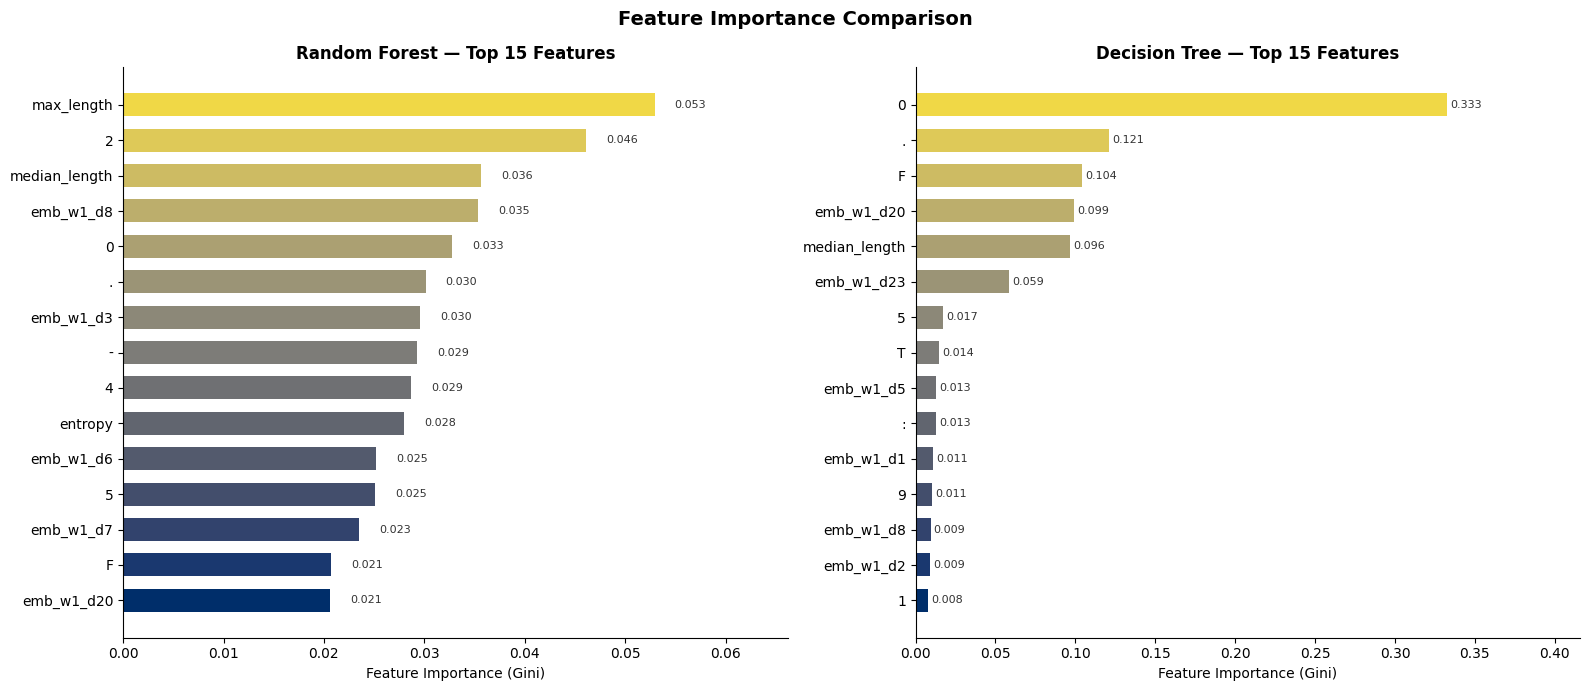

In [13]:
def plot_feature_importance(model, feature_names, top_n=15, ax=None, title=None):
    importances = model.model.feature_importances_
    top_n   = min(top_n, len(importances))
    indices = np.flip(np.argsort(importances)[-top_n:])

    importance_df = pd.DataFrame({
        'Feature':    [feature_names[i] for i in indices],
        'Importance': importances[indices],
    })

    has_std = hasattr(model.model, 'estimators_')
    if has_std:
        std = np.std([t.feature_importances_ for t in model.model.estimators_], axis=0)
        importance_df['Std'] = std[indices]

    standalone = ax is None
    if standalone:
        _, ax = plt.subplots(figsize=(7, 6))

    colors = sns.color_palette('cividis', top_n)[::-1]
    bars = ax.barh(
        importance_df['Feature'],
        importance_df['Importance'],
        color=colors,
        error_kw=dict(ecolor='#555555', capsize=3, capthick=1, elinewidth=1),
        height=0.65,
    )

    for bar, val in zip(bars, importance_df['Importance']):
        ax.text(
            bar.get_width() + 0.002, bar.get_y() + bar.get_height() / 2,
            f'{val:.3f}', va='center', ha='left', fontsize=8, color='#333333',
        )

    ax.set_xlabel('Feature Importance (Gini)', fontsize=10)
    ax.set_ylabel('')
    ax.set_title(title or f'Top {top_n} Feature Importances', fontsize=12, fontweight='bold')
    ax.set_xlim(0, importance_df['Importance'].max() * 1.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.invert_yaxis()

    if standalone:
        plt.tight_layout()
        plt.savefig('figures/feature_importance.pdf', bbox_inches='tight', dpi=300)
        plt.show()


feature_names = list(X_train.columns)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

plot_feature_importance(rf_model, feature_names, top_n=15, ax=axes[0],
                        title='Random Forest — Top 15 Features')
plot_feature_importance(dt_model, feature_names, top_n=15, ax=axes[1],
                        title='Decision Tree — Top 15 Features')

plt.suptitle('Feature Importance Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/feature_importance_comparison.pdf', bbox_inches='tight', dpi=300)
plt.savefig('figures/feature_importance_comparison.png', bbox_inches='tight', dpi=300)
plt.show()

### 5.4 Neural Network Hyperparameter Search (every configuration × every seed)
The configuration is chosen by the **mean** validation G-mean over `SEEDS`, so a lucky seed cannot pick the winner. Test metrics are recorded but never used for selection.

In [14]:
learning_rates = [0.0005, 0.0003, 0.003, 0.005, 0.001]
batch_sizes    = [512, 1024]
epochs         = 500

import pickle

# Speed: these networks are tiny, so many CPU threads mostly fight each other (and the joblib workers of the forests)
torch.set_num_threads(min(4, os.cpu_count() or 1))

# Two stages: every configuration with SEEDS[0], then only the TOP_K best (by validation) get the remaining seeds.
# Selection is still by mean validation G-mean over all seeds. TOP_K = None runs the full grid x seeds.
TOP_K = 3

# Checkpoint every finished run, so a crash or restart resumes instead of starting over.
GRID_CACHE = f"results/grid_cache/{SPLIT_NAME}_scaled{USE_SCALING}_ep{epochs}"
os.makedirs(GRID_CACHE, exist_ok=True)

grid_runs  = []   # one row per (lr, batch_size, seed)
grid_probs = {}   # (lr, batch_size, seed) -> (val probs, test probs), reused by the ensembles

def run_config(lr, batch_size, s):
    path = os.path.join(GRID_CACHE, f"lr{lr}_bs{batch_size}_seed{s}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            rec = pickle.load(f)
        tag = "cached"
    else:
        t0 = time.time()
        set_seed(s)   # seed BEFORE constructing the model
        m = ModularNeuralNetwork(criterion).to(device)
        with contextlib.redirect_stdout(io.StringIO()):
            nn_model_training_pipeline(
                X_train_nn, y_train, X_val_nn, y_val, X_test_nn, y_test, X_test_column,
                m, epochs=epochs, batch_size=batch_size,
                lr=lr, patience=75, weight_decay=1e-4, min_delta=0.001,
                monitor="val_gmean", seed=s,
            )
        rec = {'metrics': {'lr': lr, 'batch_size': batch_size, 'seed': s} | m.metrics,
               'probs': (nn_probs(m, m.val_loader), nn_probs(m, m.test_loader))}
        with open(path, "wb") as f:
            pickle.dump(rec, f)
        tag = f"{time.time() - t0:.0f}s"
    grid_runs.append(rec['metrics']); grid_probs[(lr, batch_size, s)] = rec['probs']
    mt = rec['metrics']
    print(f"lr={lr:<7} bs={batch_size:<5} seed={s:<3} val G-mean(w)={mt['best_val_metric']:.4f}  "
          f"test G-mean={mt['test_gmean']:.4f}  epochs={mt['stopped_epoch']:<4} ({tag})", flush=True)

configs = list(product(learning_rates, batch_sizes))
print(f"Stage 1: {len(configs)} configurations x seed {SEEDS[0]}")
for lr, batch_size in configs:
    run_config(lr, batch_size, SEEDS[0])

stage1 = pd.DataFrame(grid_runs).sort_values('best_val_metric', ascending=False)
finalists = configs if TOP_K is None else list(stage1[['lr', 'batch_size']].head(TOP_K).itertuples(index=False, name=None))
print(f"\nStage 2: {len(finalists)} finalists x seeds {SEEDS[1:]}")
for lr, batch_size in finalists:
    for s in SEEDS[1:]:
        run_config(lr, batch_size, s)

grid_df = pd.DataFrame(grid_runs)

# results_df: one row per configuration; scalar metrics averaged over seeds (+ *_std), curves from the SEED run
SCALARS = ['best_val_metric', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1score', 'test_gmean', 'stopped_epoch']
agg = grid_df.groupby(['lr', 'batch_size'])[SCALARS].agg(['mean', 'std'])
agg.columns = [c if stat == 'mean' else f'{c}_std' for c, stat in agg.columns]
curves = (grid_df[grid_df.seed == SEED].set_index(['lr', 'batch_size'])
          [['train_losses', 'val_losses', 'train_accuracies', 'val_accuracies', 'val_gmeans', 'confusion_matrix']])
results_df = agg.join(curves).reset_index()
results_df['n_seeds'] = grid_df.groupby(['lr', 'batch_size']).size().values

# choose only among configurations that were run with every seed
best_row = results_df[results_df.n_seeds == len(SEEDS)].sort_values('best_val_metric').iloc[-1]
best_lr, best_bs = float(best_row['lr']), int(best_row['batch_size'])
print(f"\nSelected by mean val G-mean over {len(SEEDS)} seeds: lr={best_lr}, batch_size={best_bs} "
      f"(val {best_row['best_val_metric']:.4f} ± {best_row['best_val_metric_std']:.4f})")
display(results_df[['lr', 'batch_size', 'n_seeds', 'best_val_metric', 'best_val_metric_std', 'test_gmean', 'test_gmean_std',
                    'test_accuracy', 'test_accuracy_std']].sort_values('best_val_metric', ascending=False).round(4))

Stage 1: 10 configurations x seed 42
lr=0.0005  bs=512   seed=42  val G-mean(w)=0.9879  test G-mean=0.9830  epochs=142  (cached)
lr=0.0005  bs=1024  seed=42  val G-mean(w)=0.9879  test G-mean=0.9817  epochs=177  (cached)
lr=0.0003  bs=512   seed=42  val G-mean(w)=0.9879  test G-mean=0.9830  epochs=178  (cached)
lr=0.0003  bs=1024  seed=42  val G-mean(w)=0.9879  test G-mean=0.9817  epochs=257  (cached)
lr=0.003   bs=512   seed=42  val G-mean(w)=0.9902  test G-mean=0.9861  epochs=123  (cached)
lr=0.003   bs=1024  seed=42  val G-mean(w)=0.9917  test G-mean=0.9848  epochs=142  (cached)
lr=0.005   bs=512   seed=42  val G-mean(w)=0.9921  test G-mean=0.9878  epochs=122  (cached)
lr=0.005   bs=1024  seed=42  val G-mean(w)=0.9937  test G-mean=0.9861  epochs=191  (cached)
lr=0.001   bs=512   seed=42  val G-mean(w)=0.9888  test G-mean=0.9830  epochs=111  (cached)
lr=0.001   bs=1024  seed=42  val G-mean(w)=0.9892  test G-mean=0.9835  epochs=187  (cached)

Stage 2: 3 finalists x seeds [0, 1, 2, 3]


,lr,batch_size,n_seeds,best_val_metric,best_val_metric_std,test_gmean,test_gmean_std,test_accuracy,test_accuracy_std
9,0.0050,1024,5,0.9925,0.0011,0.9856,0.0012,98.1818,0.1409
8,0.0050,512,5,0.9924,0.0004,0.9871,0.0015,98.3838,0.2259
7,0.0030,1024,5,0.9908,0.0022,0.9835,0.0030,97.8788,0.4549
6,0.0030,512,1,0.9902,NaN,0.9861,NaN,98.3165,NaN
5,0.0010,1024,1,0.9892,NaN,0.9835,NaN,97.9798,NaN
4,0.0010,512,1,0.9888,NaN,0.9830,NaN,97.9798,NaN
0,0.0003,512,1,0.9879,NaN,0.9830,NaN,97.9798,NaN
1,0.0003,1024,1,0.9879,NaN,0.9817,NaN,97.8114,NaN
2,0.0005,512,1,0.9879,NaN,0.9830,NaN,97.9798,NaN
3,0.0005,1024,1,0.9879,NaN,0.9817,NaN,97.8114,NaN


In [15]:
import sys, numpy; print(sys.executable, numpy.__version__)

/usr/local/bin/python3.11 1.26.4


### 5.5 Multi-seed Evaluation: Trees, NN and Ensemble
For every seed: a Decision Tree and a Random Forest with that `random_state`, the NN of the selected configuration trained with that seed, and the RF+NN ensemble whose alpha is tuned **on validation** for that pair. Test metrics are reported as mean ± std.

seed 42  alpha=0.5   test G-mean  DT 0.9686  RF 0.9751  NN 0.9861  Ens 0.9877
seed 0   alpha=0.7   test G-mean  DT 0.9724  RF 0.9814  NN 0.9862  Ens 0.9870
seed 1   alpha=0.7   test G-mean  DT 0.9714  RF 0.9792  NN 0.9835  Ens 0.9853
seed 2   alpha=0.7   test G-mean  DT 0.9026  RF 0.9800  NN 0.9865  Ens 0.9878
seed 3   alpha=0.7   test G-mean  DT 0.9631  RF 0.9814  NN 0.9857  Ens 0.9853


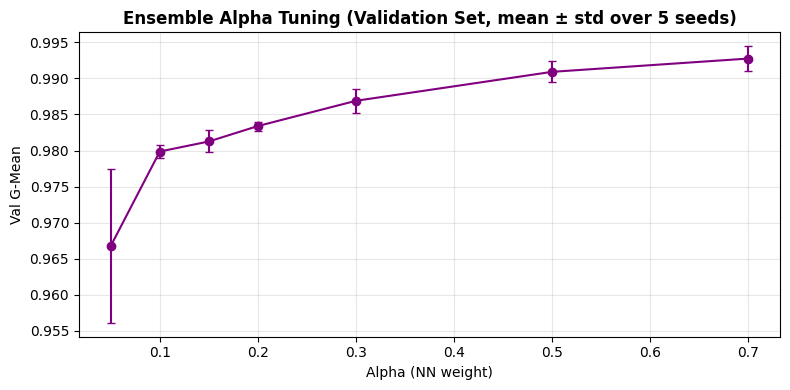

Alpha chosen per seed: {42: 0.5, 0: 0.7, 1: 0.7, 2: 0.7, 3: 0.7}


,n seeds,test_accuracy,test_f1score,test_gmean
Decision Tree,5,95.42 ± 1.34,0.9544 ± 0.0135,0.9556 ± 0.0299
Random Forest,5,97.04 ± 0.35,0.9707 ± 0.0035,0.9794 ± 0.0026
Neural Network,5,98.18 ± 0.14,0.9818 ± 0.0014,0.9856 ± 0.0012
Ensemble,5,98.22 ± 0.19,0.9822 ± 0.0019,0.9866 ± 0.0013


In [16]:
ALPHAS   = [0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.7]
y_tr_i   = y_train['DataType'].astype(int).values
y_val_i  = y_val['DataType'].astype(int).values
y_test_i = y_test['DataType'].astype(int).values
gm = lambda y, p: geometric_mean_score(y, p, average='multiclass')

seed_runs = {'Decision Tree': [], 'Random Forest': [], 'Neural Network': [], 'Ensemble': []}
alpha_curves, chosen_alphas = [], []
for s in SEEDS:
    dt_s = clone(dt).set_params(random_state=s).fit(X_train, y_tr_i)
    rf_s = clone(rf).set_params(random_state=s).fit(X_train, y_tr_i)
    rf_v, rf_t = rf_s.predict_proba(X_val), rf_s.predict_proba(X_test)
    nn_v, nn_t = grid_probs[(best_lr, best_bs, s)]

    val_g = [gm(y_val_i, (a * nn_v + (1 - a) * rf_v).argmax(1)) for a in ALPHAS]
    a = ALPHAS[int(np.argmax(val_g))]
    alpha_curves.append(val_g); chosen_alphas.append(a)

    seed_runs['Decision Tree'].append(classification_metrics(y_test_i, dt_s.predict(X_test)) | {'seed': s})
    seed_runs['Random Forest'].append(classification_metrics(y_test_i, rf_t.argmax(1)) | {'seed': s})
    seed_runs['Neural Network'].append(classification_metrics(y_test_i, nn_t.argmax(1)) | {'seed': s})
    seed_runs['Ensemble'].append(classification_metrics(y_test_i, (a * nn_t + (1 - a) * rf_t).argmax(1)) | {'seed': s, 'alpha': a})
    print(f"seed {s:<3} alpha={a:<4}  test G-mean  DT {seed_runs['Decision Tree'][-1]['test_gmean']:.4f}  "
          f"RF {seed_runs['Random Forest'][-1]['test_gmean']:.4f}  NN {seed_runs['Neural Network'][-1]['test_gmean']:.4f}  "
          f"Ens {seed_runs['Ensemble'][-1]['test_gmean']:.4f}")

A = np.array(alpha_curves)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(ALPHAS, A.mean(0), yerr=A.std(0, ddof=1) if len(SEEDS) > 1 else None,
            marker='o', color='purple', capsize=3)
ax.set_xlabel('Alpha (NN weight)')
ax.set_ylabel('Val G-Mean')
ax.set_title(f'Ensemble Alpha Tuning (Validation Set, mean ± std over {len(SEEDS)} seeds)', fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/ensemble_alpha_tuning.pdf', bbox_inches='tight', dpi=300)
plt.savefig('figures/ensemble_alpha_tuning.png', bbox_inches='tight', dpi=300)
plt.show()

print("Alpha chosen per seed:", dict(zip(SEEDS, chosen_alphas)))
display(mean_std_table(seed_runs))

## 6. Results

### 6.1 Neural Network Hyperparameter Analysis

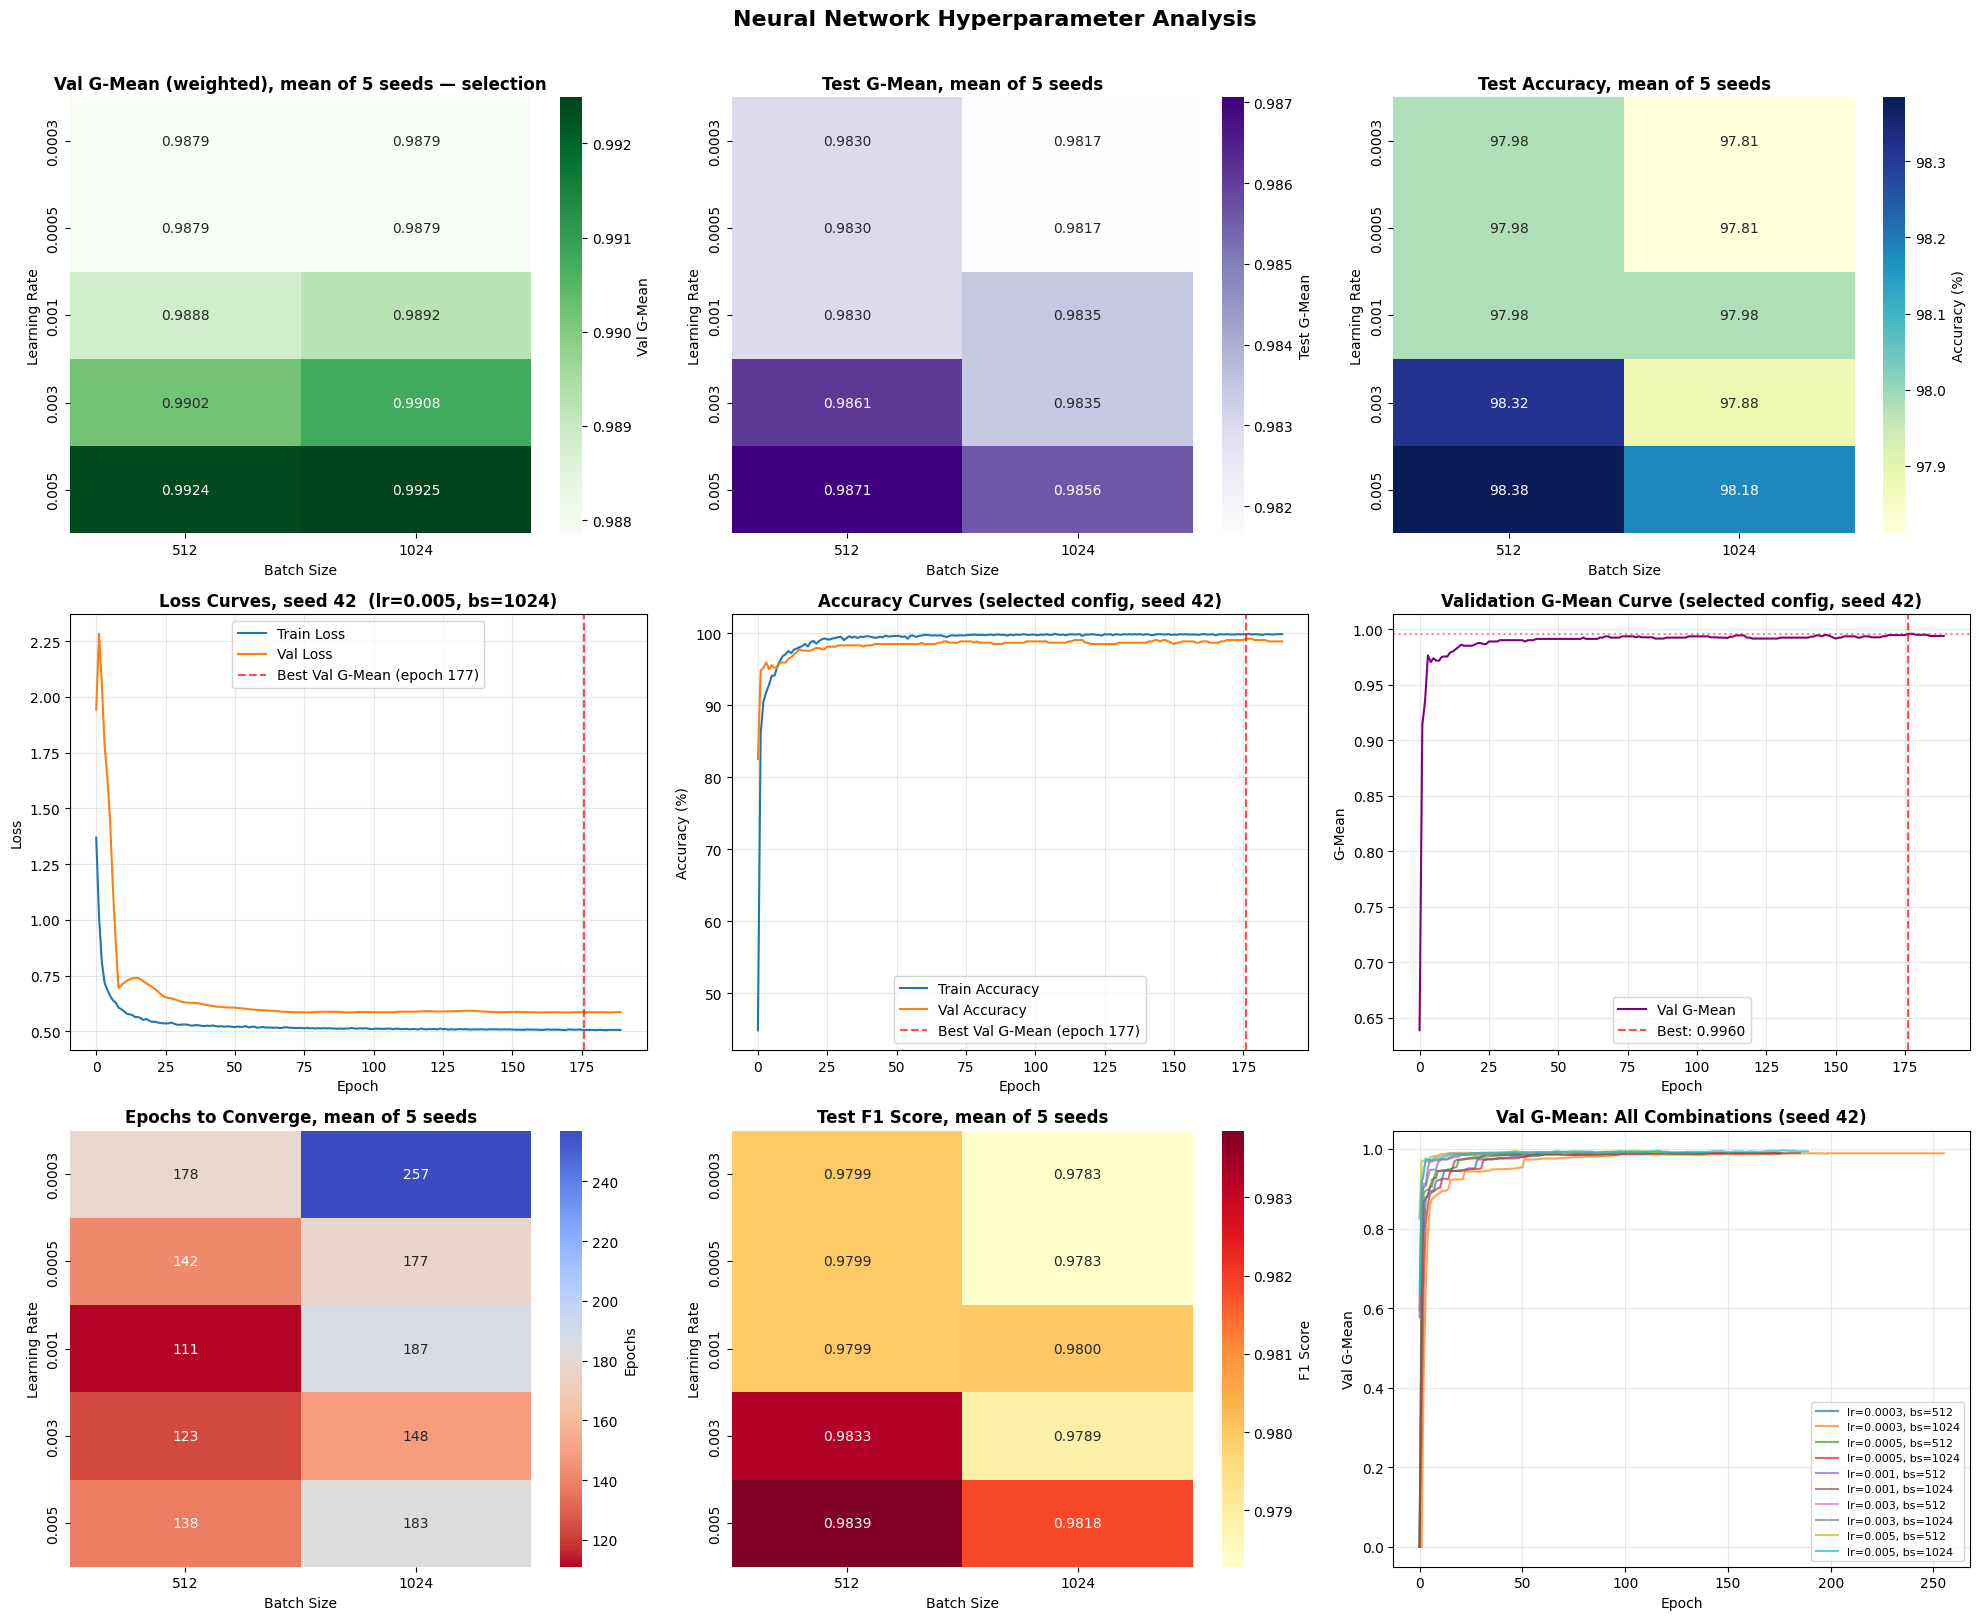

In [17]:
best_model_metrics = results_df.loc[results_df['best_val_metric'].idxmax()]

fig = plt.figure(figsize=(20, 16))

# Row 1: Heatmaps
plt.subplot(3, 3, 1)
pivot_val_gmean = results_df.pivot(index='lr', columns='batch_size', values='best_val_metric')
sns.heatmap(pivot_val_gmean, annot=True, fmt='.4f', cmap='Greens', cbar_kws={'label': 'Val G-Mean'})
plt.title(f'Val G-Mean (weighted), mean of {len(SEEDS)} seeds — selection', fontsize=12, fontweight='bold')
plt.xlabel('Batch Size'); plt.ylabel('Learning Rate')

plt.subplot(3, 3, 2)
pivot_gmean = results_df.pivot(index='lr', columns='batch_size', values='test_gmean')
sns.heatmap(pivot_gmean, annot=True, fmt='.4f', cmap='Purples', cbar_kws={'label': 'Test G-Mean'})
plt.title(f'Test G-Mean, mean of {len(SEEDS)} seeds', fontsize=12, fontweight='bold')
plt.xlabel('Batch Size'); plt.ylabel('Learning Rate')

plt.subplot(3, 3, 3)
pivot_accuracy = results_df.pivot(index='lr', columns='batch_size', values='test_accuracy')
sns.heatmap(pivot_accuracy, annot=True, fmt='.2f', cmap='YlGnBu', cbar_kws={'label': 'Accuracy (%)'})
plt.title(f'Test Accuracy, mean of {len(SEEDS)} seeds', fontsize=12, fontweight='bold')
plt.xlabel('Batch Size'); plt.ylabel('Learning Rate')

# Row 2: Training curves for best model
train_losses     = best_model_metrics['train_losses']
val_losses       = best_model_metrics['val_losses']
train_accs       = best_model_metrics['train_accuracies']
val_accs         = best_model_metrics['val_accuracies']
val_gmeans       = best_model_metrics['val_gmeans']
best_gmean_epoch = val_gmeans.index(max(val_gmeans))

plt.subplot(3, 3, 4)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses,   label='Val Loss')
plt.axvline(x=best_gmean_epoch, color='red', linestyle='--', alpha=0.7,
            label=f'Best Val G-Mean (epoch {best_gmean_epoch + 1})')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title(f'Loss Curves, seed {SEED}  (lr={best_model_metrics["lr"]}, bs={best_model_metrics["batch_size"]})',
          fontsize=12, fontweight='bold')
plt.legend(); plt.grid(True, alpha=0.3)

plt.subplot(3, 3, 5)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(val_accs,   label='Val Accuracy')
plt.axvline(x=best_gmean_epoch, color='red', linestyle='--', alpha=0.7,
            label=f'Best Val G-Mean (epoch {best_gmean_epoch + 1})')
plt.xlabel('Epoch'); plt.ylabel('Accuracy (%)')
plt.title(f'Accuracy Curves (selected config, seed {SEED})', fontsize=12, fontweight='bold')
plt.legend(); plt.grid(True, alpha=0.3)

plt.subplot(3, 3, 6)
plt.plot(val_gmeans, label='Val G-Mean', color='purple')
plt.axvline(x=best_gmean_epoch, color='red', linestyle='--', alpha=0.7,
            label=f'Best: {max(val_gmeans):.4f}')
plt.axhline(y=max(val_gmeans), color='red', linestyle=':', alpha=0.5)
plt.xlabel('Epoch'); plt.ylabel('G-Mean')
plt.title(f'Validation G-Mean Curve (selected config, seed {SEED})', fontsize=12, fontweight='bold')
plt.legend(); plt.grid(True, alpha=0.3)

# Row 3: Convergence + F1 heatmap + all G-Mean curves
plt.subplot(3, 3, 7)
pivot_epochs = results_df.pivot(index='lr', columns='batch_size', values='stopped_epoch')
sns.heatmap(pivot_epochs, annot=True, fmt='.0f', cmap='coolwarm_r', cbar_kws={'label': 'Epochs'})
plt.title(f'Epochs to Converge, mean of {len(SEEDS)} seeds', fontsize=12, fontweight='bold')
plt.xlabel('Batch Size'); plt.ylabel('Learning Rate')

plt.subplot(3, 3, 8)
pivot_f1 = results_df.pivot(index='lr', columns='batch_size', values='test_f1score')
sns.heatmap(pivot_f1, annot=True, fmt='.4f', cmap='YlOrRd', cbar_kws={'label': 'F1 Score'})
plt.title(f'Test F1 Score, mean of {len(SEEDS)} seeds', fontsize=12, fontweight='bold')
plt.xlabel('Batch Size'); plt.ylabel('Learning Rate')

plt.subplot(3, 3, 9)
for _, row in results_df.iterrows():
    plt.plot(row['val_gmeans'], label=f"lr={row['lr']}, bs={row['batch_size']}", alpha=0.7)
plt.xlabel('Epoch'); plt.ylabel('Val G-Mean')
plt.title(f'Val G-Mean: All Combinations (seed {SEED})', fontsize=12, fontweight='bold')
plt.legend(fontsize=8); plt.grid(True, alpha=0.3)

plt.suptitle('Neural Network Hyperparameter Analysis', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/nn_hyperparameter_analysis.pdf', bbox_inches='tight', dpi=300)
plt.savefig('figures/nn_hyperparameter_analysis.png', bbox_inches='tight', dpi=300)
plt.show()

### 6.2 Pandas Baseline

In [18]:
PANDAS_LABELENCODER = {
    'object':         '0',  # varchar
    'int64':          '1',  # number
    'float64':        '1',
    'int32':          '1',
    'float32':        '1',
    'bool':           '2',  # boolean
    'datetime64[ns]': '3',  # datetime
    'timedelta[ns]':  '3',
}

y_pandas_labels  = pd.read_csv(DATA_DIR + 'y_pandas.csv')
y_pandas_encoded = y_pandas_labels['PandasDataType'].map(PANDAS_LABELENCODER)

unmapped = y_pandas_labels['PandasDataType'][y_pandas_encoded.isna()].unique()
if len(unmapped) > 0:
    print(f"Warning: unmapped pandas types (defaulting to varchar/0): {unmapped}")
    y_pandas_encoded = y_pandas_encoded.fillna('0')

y_pandas_encoded = y_pandas_encoded.astype(str)
y_test_arr       = y_test_labels['DataType'].map(LABELENCODER).values.ravel().astype(str)
y_pandas_arr     = y_pandas_encoded.values.ravel()

mis_idx = np.where(y_test_arr != y_pandas_arr)[0]
if len(mis_idx) > 0:
    X_test_column_reset = X_test_column.reset_index(drop=True)
    misclassified_df = pd.DataFrame({
        'Feature_Value': X_test_column_reset.iloc[mis_idx].values,
        'Actual':        y_test_arr[mis_idx],
        'Predicted':     y_pandas_arr[mis_idx],
    })
    print("\nMisclassified samples with predictions:")
    print(misclassified_df)

pandas_metrics = {
    'test_accuracy':    accuracy_score(y_test_arr, y_pandas_arr) * 100,
    'test_precision':   precision_score(y_test_arr, y_pandas_arr, average='weighted', zero_division=0) * 100,
    'test_recall':      recall_score(y_test_arr, y_pandas_arr, average='weighted', zero_division=0) * 100,
    'test_f1score':     f1_score(y_test_arr, y_pandas_arr, average='weighted', zero_division=0),
    'test_gmean':       geometric_mean_score(y_test_arr, y_pandas_arr, average='multiclass'),
    'confusion_matrix': confusion_matrix(y_test_arr, y_pandas_arr),
}

print("Pandas Baseline:")
print(f"  Test Accuracy : {pandas_metrics['test_accuracy']:.2f}%")
print(f"  Test F1       : {pandas_metrics['test_f1score']:.4f}")
print(f"  Test G-Mean   : {pandas_metrics['test_gmean']:.4f}")


Misclassified samples with predictions:
        Feature_Value Actual Predicted
0          Data As Of      3         0
1      Data Loaded At      3         0
2            Filer Id      0         1
3         Filing Date      3         0
4           Filing Id      0         1
..                ...    ...       ...
59         start_date      3         0
60         updated_at      3         0
61         created_at      3         0
62           due_date      3         0
63  ('timestamp', '')      3         0

[64 rows x 3 columns]
Pandas Baseline:
  Test Accuracy : 89.23%
  Test F1       : 0.8572
  Test G-Mean   : 0.0000


### 6.3 Model Comparison: Bar Charts and Summary Table (mean ± std over seeds)
*Single split (section 3), so the ± only reflects training noise. The headline numbers over many unseen-table and unseen-source splits are in §15.*

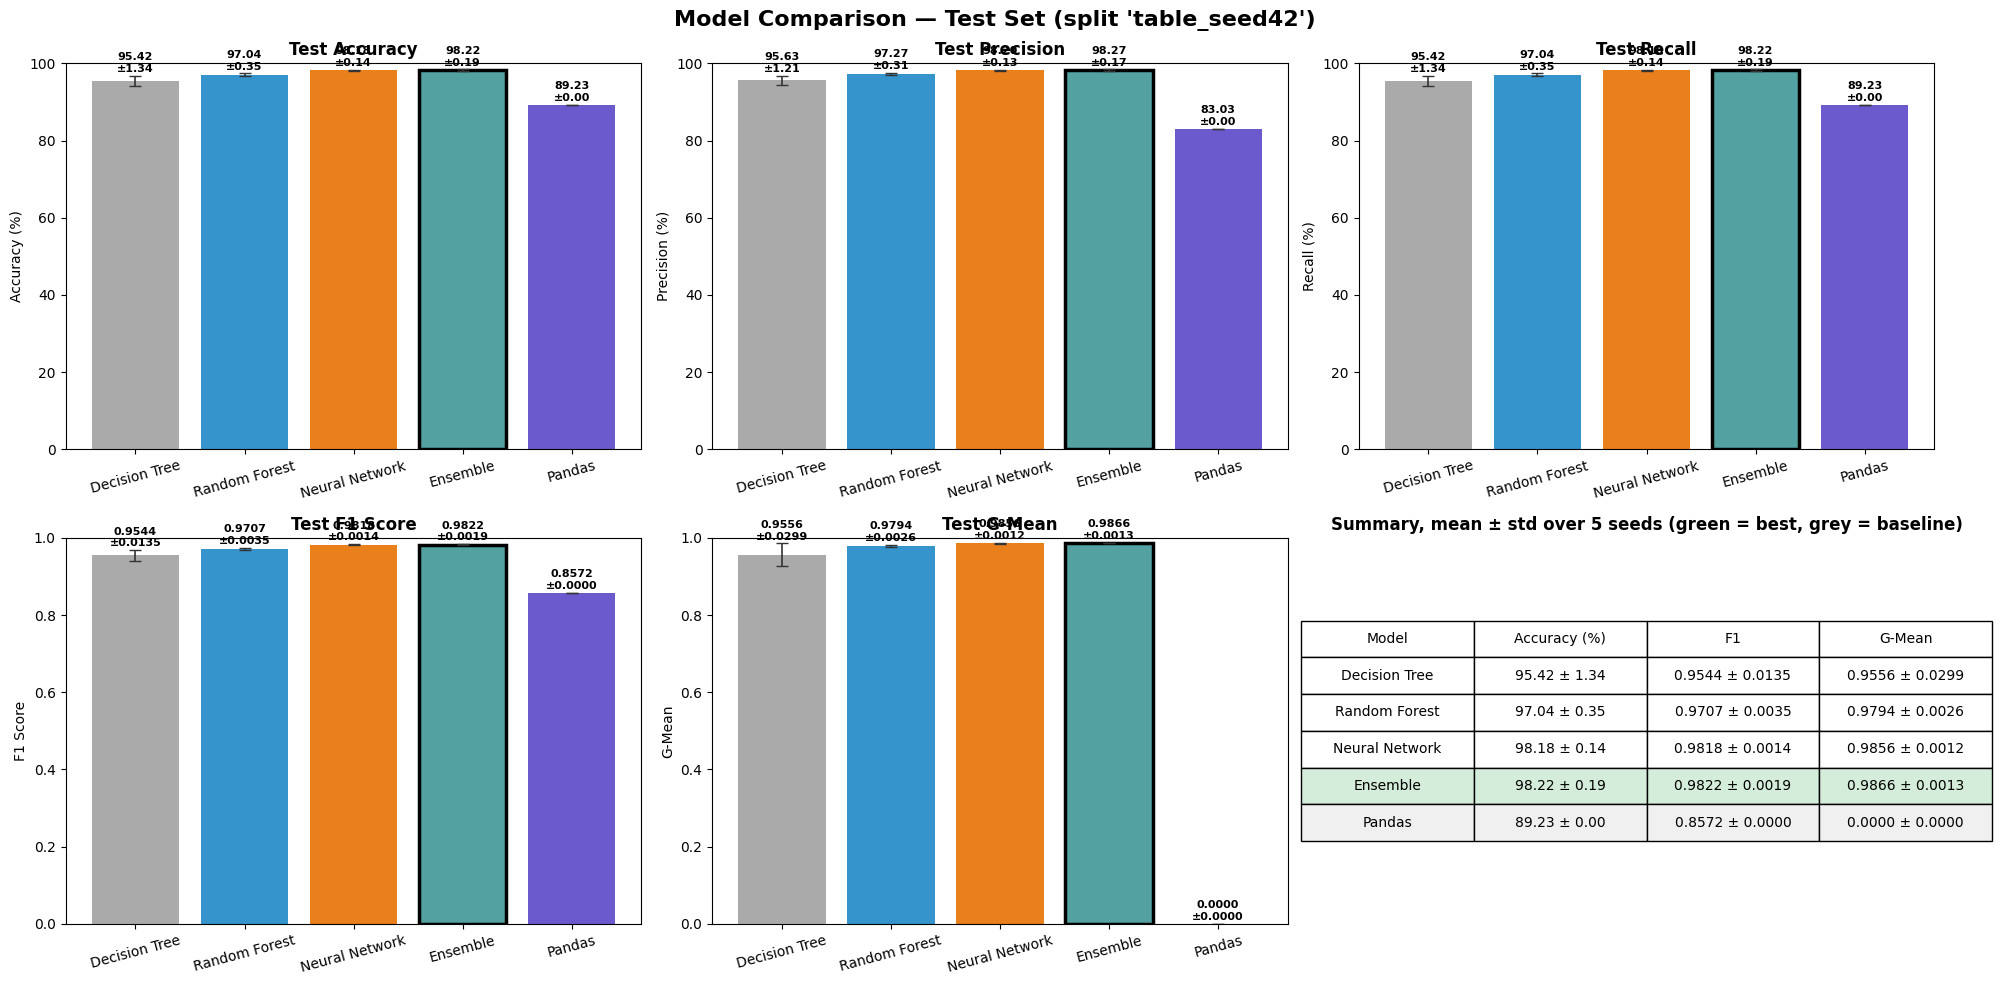


MODEL SELECTION SUMMARY (mean ± std over 5 seeds)

Decision Tree:
  Test Accuracy : 95.42 ± 1.34%
  Test F1       : 0.9544 ± 0.0135
  Test G-Mean   : 0.9556 ± 0.0299

Random Forest:
  Test Accuracy : 97.04 ± 0.35%
  Test F1       : 0.9707 ± 0.0035
  Test G-Mean   : 0.9794 ± 0.0026

Neural Network:
  Test Accuracy : 98.18 ± 0.14%
  Test F1       : 0.9818 ± 0.0014
  Test G-Mean   : 0.9856 ± 0.0012

Ensemble:
  Test Accuracy : 98.22 ± 0.19%
  Test F1       : 0.9822 ± 0.0019
  Test G-Mean   : 0.9866 ± 0.0013

Pandas ← baseline:
  Test Accuracy : 89.23 ± 0.00%
  Test F1       : 0.8572 ± 0.0000
  Test G-Mean   : 0.0000 ± 0.0000

→ Best model by mean G-Mean: Ensemble (0.9866 ± 0.0013)
→ Pandas G-Mean is 0 (it never predicts one of the classes); absolute gain +0.9866


In [19]:
results_runs = dict(seed_runs) | {'Pandas': [pandas_metrics]}   # pandas is deterministic: one run
models = list(results_runs)
KEYS = ['test_accuracy', 'test_precision', 'test_recall', 'test_f1score', 'test_gmean']
mean = {m: {k: float(np.mean([r[k] for r in L])) for k in KEYS} for m, L in results_runs.items()}
std  = {m: {k: float(np.std([r[k] for r in L], ddof=1)) if len(L) > 1 else 0.0 for k in KEYS} for m, L in results_runs.items()}

colors = ['#aaaaaa', '#3594cc', '#ea801c', '#54a1a1', '#6a5acd']

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()

metric_configs = [
    ('test_accuracy',  'Accuracy (%)',  'Test Accuracy',  '{:.2f}', 1,    [0, 100]),
    ('test_precision', 'Precision (%)', 'Test Precision', '{:.2f}', 1,    [0, 100]),
    ('test_recall',    'Recall (%)',    'Test Recall',    '{:.2f}', 1,    [0, 100]),
    ('test_f1score',   'F1 Score',      'Test F1 Score',  '{:.4f}', 0.01, [0, 1]),
    ('test_gmean',     'G-Mean',        'Test G-Mean',    '{:.4f}', 0.01, [0, 1]),
]

for ax, (key, ylabel, title, fmt, offset, ylim) in zip(axes, metric_configs):
    values = [mean[m][key] for m in models]
    errs   = [std[m][key] for m in models]
    bars   = ax.bar(models, values, yerr=errs, capsize=4, color=colors, error_kw=dict(ecolor='#333333', lw=1.2))
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight='bold')
    ax.set_ylim(ylim)
    ax.tick_params(axis='x', rotation=15)
    for i, (v, e) in enumerate(zip(values, errs)):
        ax.text(i, v + e + offset, (fmt + '\n±' + fmt).format(v, e), ha='center', fontweight='bold', fontsize=8)
    best_idx = int(np.argmax(values))
    bars[best_idx].set_edgecolor('black')
    bars[best_idx].set_linewidth(2.5)

# Summary table
ax = axes[5]
ax.axis('off')
table_data = [
    [m,
     f"{mean[m]['test_accuracy']:.2f} ± {std[m]['test_accuracy']:.2f}",
     f"{mean[m]['test_f1score']:.4f} ± {std[m]['test_f1score']:.4f}",
     f"{mean[m]['test_gmean']:.4f} ± {std[m]['test_gmean']:.4f}"]
    for m in models
]
table = ax.table(
    cellText=table_data,
    colLabels=['Model', 'Accuracy (%)', 'F1', 'G-Mean'],
    cellLoc='center',
    loc='center',
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 2)

gmeans   = [mean[m]['test_gmean'] for m in models]
best_row = int(np.argmax(gmeans)) + 1
for col in range(4):
    table[best_row, col].set_facecolor('#d4edda')

pandas_row = list(models).index('Pandas') + 1
for col in range(4):
    table[pandas_row, col].set_facecolor('#f0f0f0')

ax.set_title(f'Summary, mean ± std over {len(SEEDS)} seeds (green = best, grey = baseline)', fontweight='bold')

plt.suptitle(f"Model Comparison — Test Set (split '{SPLIT_NAME}')", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/model_comparison_bar.pdf', bbox_inches='tight', dpi=300)
plt.savefig('figures/model_comparison_bar.png', bbox_inches='tight', dpi=300)
plt.show()

# Print summary
print("\n" + "=" * 50)
print(f"MODEL SELECTION SUMMARY (mean ± std over {len(SEEDS)} seeds)")
print("=" * 50)
for m in models:
    tag = " ← baseline" if m == 'Pandas' else ""
    print(f"\n{m}{tag}:")
    print(f"  Test Accuracy : {mean[m]['test_accuracy']:.2f} ± {std[m]['test_accuracy']:.2f}%")
    print(f"  Test F1       : {mean[m]['test_f1score']:.4f} ± {std[m]['test_f1score']:.4f}")
    print(f"  Test G-Mean   : {mean[m]['test_gmean']:.4f} ± {std[m]['test_gmean']:.4f}")

best_model   = models[int(np.argmax(gmeans))]
pandas_gmean = mean['Pandas']['test_gmean']
best_gmean   = mean[best_model]['test_gmean']
print(f"\n→ Best model by mean G-Mean: {best_model} ({best_gmean:.4f} ± {std[best_model]['test_gmean']:.4f})")
if pandas_gmean > 0:
    print(f"→ Improvement over Pandas  : +{(best_gmean - pandas_gmean) / pandas_gmean * 100:.1f}%")
else:
    print(f"→ Pandas G-Mean is 0 (it never predicts one of the classes); absolute gain +{best_gmean:.4f}")

### 6.4 Confusion Matrix Comparison (Main Models, summed over seeds)

/var/folders/hg/fq57sy157xxf2tb_3b7nc79r0000gn/T/ipykernel_42973/11709484.py:54: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.92, 1])


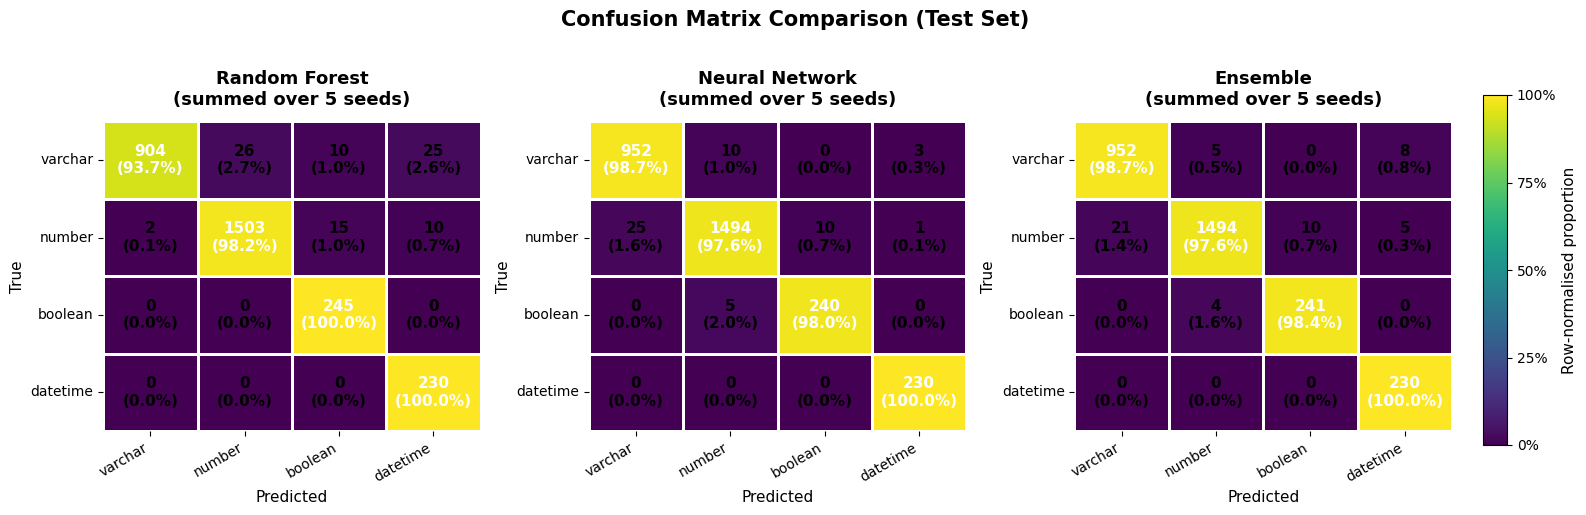

In [20]:
def plot_confusion_matrix_accessible(cm, class_names, model_name, ax):
    cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    sns.heatmap(
        cm_normalized,
        annot=False,
        cmap='viridis',
        vmin=0, vmax=1,
        linewidths=0.8,
        linecolor='white',
        ax=ax,
        cbar=False,
    )

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            count      = cm[i, j]
            pct        = cm_normalized[i, j] * 100
            text_color = 'white' if cm_normalized[i, j] > 0.5 else 'black'
            ax.text(
                j + 0.5, i + 0.5,
                f'{count}\n({pct:.1f}%)',
                ha='center', va='center',
                fontsize=11, fontweight='bold',
                color=text_color,
            )

    ax.set_title(model_name, fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('Predicted', fontsize=11)
    ax.set_ylabel('True', fontsize=11)
    ax.set_xticklabels(class_names, rotation=30, ha='right', fontsize=10)
    ax.set_yticklabels(class_names, rotation=0, fontsize=10)


class_names = ['varchar', 'number', 'boolean', 'datetime']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, model_name in zip(axes, ['Random Forest', 'Neural Network', 'Ensemble']):
    cm_sum = np.sum([r['confusion_matrix'] for r in seed_runs[model_name]], axis=0)
    plot_confusion_matrix_accessible(
        cm_sum, class_names, f"{model_name}\n(summed over {len(SEEDS)} seeds)", ax,
    )

cbar_ax = fig.add_axes([0.93, 0.15, 0.015, 0.7])
sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=0, vmax=1))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('Row-normalised proportion', fontsize=11)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels(['0%', '25%', '50%', '75%', '100%'])

plt.suptitle('Confusion Matrix Comparison (Test Set)',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout(rect=[0, 0, 0.92, 1])
plt.savefig('figures/confusion_matrices_main.pdf', bbox_inches='tight', dpi=300)
plt.savefig('figures/confusion_matrices_main.png', bbox_inches='tight', dpi=300)
plt.show()

## 7. Subnetwork Contributions in the Modular Neural Network

### 7.1 Statistics Subnetwork (all seeds)

In [21]:
print(f"Learning Rate: {best_lr}, Batch Size: {best_bs}, seeds: {SEEDS}")
subnet_runs = {'Stats Neural Network': [], 'Col Name Neural Network': []}

for s in SEEDS:
    set_seed(s)
    stats_nn_model = StatsNeuralNetwork(criterion).to(device)
    with contextlib.redirect_stdout(io.StringIO()):
        nn_model_training_pipeline(
            X_train_nn, y_train, X_val_nn, y_val, X_test_nn, y_test, X_test_column,
            stats_nn_model, epochs=epochs, batch_size=best_bs,
            lr=best_lr, patience=20, weight_decay=5e-3, min_delta=0.001,
            monitor="val_gmean", seed=s,
        )
    subnet_runs['Stats Neural Network'].append({k: stats_nn_model.metrics[k] for k in METRIC_KEYS} | {'seed': s})
    print(f"seed {s:<3} test G-mean {stats_nn_model.metrics['test_gmean']:.4f}  acc {stats_nn_model.metrics['test_accuracy']:.2f}%")

Learning Rate: 0.005, Batch Size: 1024, seeds: [42, 0, 1, 2, 3]


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seed 42  test G-mean 0.9701  acc 96.30%
seed 0   test G-mean 0.9682  acc 96.13%
seed 1   test G-mean 0.9715  acc 96.46%
seed 2   test G-mean 0.9672  acc 96.46%
seed 3   test G-mean 0.9690  acc 96.30%


### 7.2 Column Name Subnetwork (all seeds)

In [22]:
for s in SEEDS:
    set_seed(s)
    colname_nn_model = ColNameNeuralNetwork(criterion).to(device)
    with contextlib.redirect_stdout(io.StringIO()):
        nn_model_training_pipeline(
            X_train_nn, y_train, X_val_nn, y_val, X_test_nn, y_test, X_test_column,
            colname_nn_model, epochs=epochs, batch_size=best_bs,
            lr=best_lr, patience=20, weight_decay=5e-3, min_delta=0.001,
            monitor="val_gmean", seed=s,
        )
    subnet_runs['Col Name Neural Network'].append({k: colname_nn_model.metrics[k] for k in METRIC_KEYS} | {'seed': s})
    print(f"seed {s:<3} test G-mean {colname_nn_model.metrics['test_gmean']:.4f}  acc {colname_nn_model.metrics['test_accuracy']:.2f}%")

seed 42  test G-mean 0.8325  acc 90.74%
seed 0   test G-mean 0.8239  acc 89.73%
seed 1   test G-mean 0.8348  acc 89.90%
seed 2   test G-mean 0.8330  acc 90.07%
seed 3   test G-mean 0.8212  acc 90.74%


In [23]:
display(mean_std_table(subnet_runs | {'Modular NN (both inputs)': seed_runs['Neural Network']}))

,n seeds,test_accuracy,test_f1score,test_gmean
Stats Neural Network,5,96.33 ± 0.14,0.9631 ± 0.0014,0.9692 ± 0.0017
Col Name Neural Network,5,90.24 ± 0.48,0.8992 ± 0.0043,0.8291 ± 0.0061
Modular NN (both inputs),5,98.18 ± 0.14,0.9818 ± 0.0014,0.9856 ± 0.0012


## 8. Robustness over random seeds
A single seed can land anywhere in a ±1–2 point band on a small test set. Here RF (10 seeds), the NN (the `SEEDS` runs of the selected configuration from §5.4) and **every** RF×NN pairing for the ensemble (alpha re-selected on validation for each pairing) are reported as mean ± std. (Before this revision the NN runs here shared batch order and dropout masks because the training pipeline re-seeded with the global `SEED`.)

In [24]:
RF_SEEDS, NN_SEEDS = [42] + list(range(9)), SEEDS

rf_p, rf_rows = {}, []
for s in RF_SEEDS:
    m = clone(rf).set_params(random_state=s, n_jobs=-1).fit(X_train, y_tr_i)
    rf_p[s] = (m.predict_proba(X_val), m.predict_proba(X_test))
    rf_rows.append(classification_metrics(y_test_i, rf_p[s][1].argmax(1)))

nn_p, nn_rows = {}, []
for s in NN_SEEDS:
    if (best_lr, best_bs, s) in grid_probs:            # already trained in the §5.4 grid search
        nn_p[s] = grid_probs[(best_lr, best_bs, s)]
    else:
        set_seed(s)
        m = ModularNeuralNetwork(criterion).to(device)
        with contextlib.redirect_stdout(io.StringIO()):
            nn_model_training_pipeline(X_train_nn, y_train, X_val_nn, y_val, X_test_nn, y_test, X_test_column, m,
                                       epochs=epochs, batch_size=best_bs, lr=best_lr, patience=75,
                                       weight_decay=1e-4, min_delta=0.001, monitor="val_gmean", seed=s)
        nn_p[s] = (nn_probs(m, m.val_loader), nn_probs(m, m.test_loader))
    nn_rows.append(classification_metrics(y_test_i, nn_p[s][1].argmax(1)))

ens_rows = []
for r in RF_SEEDS:
    for n in NN_SEEDS:
        val_g = [gm(y_val_i, (a*nn_p[n][0] + (1-a)*rf_p[r][0]).argmax(1)) for a in ALPHAS]
        a = ALPHAS[int(np.argmax(val_g))]
        ens_rows.append(classification_metrics(y_test_i, (a*nn_p[n][1] + (1-a)*rf_p[r][1]).argmax(1)) | {'alpha': a})

seed_table = mean_std_table({f"Random Forest": rf_rows, f"Modular NN": nn_rows, f"RF + NN ensemble (all pairings)": ens_rows})
seed_table

,n seeds,test_accuracy,test_f1score,test_gmean
Random Forest,10,96.89 ± 0.31,0.9692 ± 0.0031,0.9785 ± 0.0022
Modular NN,5,98.18 ± 0.14,0.9818 ± 0.0014,0.9856 ± 0.0012
RF + NN ensemble (all pairings),50,98.24 ± 0.16,0.9825 ± 0.0016,0.9864 ± 0.0019


---
# Extended evaluation (sections 9–14)

Sections 1–8 reproduce the paper's pipeline. The sections below stress-test its claims:

| § | Question |
|---|---|
| 10 | How much do the headline numbers move with the random seed? (bootstrap CIs, paper values overlaid) |
| 11 | How optimistic is a random column-level split? (leakage diagnostic; table- and source-grouped splits) |
| 12 | What does standardizing the NN inputs change? |
| 13 | Which feature groups matter? (statistics vs. column-name embeddings, per class) |
| 14 | Is 25 PCA components a good choice for the embeddings? (selected on validation) |

**How it runs.** Every experiment is a function with cached output in `results/`. By default the notebook *loads* the cache and only draws figures (seconds). Set `RUN_EXPERIMENTS = True` to recompute and overwrite the cache (≈40 min on a single CPU core); `QUICK = True` runs tiny versions into `results_quick/` purely to smoke-test the code.

## 9. Setup for the extended evaluation

In [25]:
import os, io, json, time, contextlib
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score
from imblearn.metrics import geometric_mean_score
import matplotlib.pyplot as plt
import seaborn as sns

RUN_EXPERIMENTS = False   # True: recompute everything and overwrite results/*.json (~40 min on 1 CPU)
QUICK           = False   # True: tiny settings for smoke-testing the code paths (writes to results_quick/)

X_DATA    = "data/"     # raw feature files (grouped / random re-splits in §11 are rebuilt from these)
SPLIT_DIR = DATA_DIR    # "the" split for §10, §12–14: whatever section 3 loaded (SPLIT_NAME)
# NN hyper-parameters: the configuration selected in §5.4 (previously hard-coded to lr=0.005, bs=512)
X_NN_LR = float(globals().get("best_lr", 0.005))
X_NN_BS = int(globals().get("best_bs", 512))
# cache per split + NN hyper-parameters, so results from different settings never get mixed up
RESULTS_DIR = os.path.join("results_quick" if QUICK else "results", f"{SPLIT_NAME}_lr{X_NN_LR}_bs{X_NN_BS}_scaled{USE_SCALING}")
# label for the NN variant used throughout §10–§15 (follows USE_SCALING from section 3.1)
NN_TAG  = "z-scored" if USE_SCALING else "unscaled"
ALT_TAG = "unscaled" if USE_SCALING else "z-scored"   # the opposite variant, trained only for the §11/§12 comparison
print(f"Split: {SPLIT_NAME} | NN lr={X_NN_LR}, bs={X_NN_BS}, inputs {NN_TAG} | cache: {RESULTS_DIR}")
os.makedirs(RESULTS_DIR, exist_ok=True)   # makedirs handles the nested folder
os.makedirs("figures", exist_ok=True)   # figures written by sections 1-8

SEEDS_DT      = [42] + list(range(9))  if not QUICK else [42, 0]
SEEDS_RF      = [42] + list(range(19)) if not QUICK else [42, 0, 1]
SEEDS_NN      = [42] + list(range(9))  if not QUICK else [42, 0]
NN_ABL_SEEDS  = [42, 0, 1]             if not QUICK else [42]
BOOT          = 2000                   if not QUICK else 200
N_SPLITS      = 5                      if not QUICK else 1
SPLIT_MODEL_SEEDS = [42, 0, 1]         if not QUICK else [42]   # §11: model seeds trained on every split

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Split: table_seed42 | NN lr=0.005, bs=1024, inputs z-scored | cache: results/table_seed42_lr0.005_bs1024_scaledTrue


In [26]:
# ---- helpers (feature rebuild with source paths, metrics, model wrappers) ----

X_LAB={'varchar':0,'number':1,'boolean':2,'time':3,'date':3,'timestamp':3}
X_PANDAS={'object':0,'int64':1,'float64':1,'int32':1,'float32':1,'bool':2,'datetime64[ns]':3,'timedelta[ns]':3}
X_ALPHAS=[0.05,0.1,0.15,0.2,0.3,0.5,0.7]
X_DROP6=[']','}',')','mean_length','skew_length','min_length']

def x_key(names, S):
    """Row key: column name + rounded statistics. Rounding to 6 decimals first mirrors the %.6f used when the
    split CSVs were saved, so raw and saved values round identically (a plain round(5) matched only ~60% of rows)."""
    return names.astype(str)+'#'+S.astype(float).round(6).round(5).astype(str).agg('|'.join,axis=1)

def x_build_base():
    df=pd.concat([pd.read_csv(X_DATA+f) for f in ['features_viznet_train_auto_labeled_subset.csv','features_non_viznet_auto_labeled.csv','features_gittables_auto_labeled.csv']],ignore_index=True)
    df.fillna({'skew_length':0.0},inplace=True); df.fillna({'kurtosis_length':-3.0},inplace=True)
    df=df[~(df.iloc[:,4:98]==0).all(axis=1)]
    df=df.drop(['column_name_segments','num_of_segments'],axis=1)
    df=df[~df.drop(columns=['Filepath']).duplicated()].reset_index(drop=True)
    embc=[c for c in df.columns if c.startswith('emb_w')]
    meta=df[['ColumnName','Filepath','DataType','PandasDataType']].copy()
    meta['y']=meta.DataType.map(X_LAB).astype(int)
    meta['ypd']=meta.PandasDataType.map(X_PANDAS).fillna(0).astype(int)
    stat=df.drop(columns=['ColumnName','Filepath','DataType','PandasDataType']+embc+X_DROP6)
    assert stat.shape[1]==95, stat.shape
    raw=[df[[c for c in embc if c.startswith(f'emb_w{i}_')]].values for i in range(1,9)]
    meta['k']=x_key(meta.ColumnName,stat)
    return dict(meta=meta,stat=stat,raw=raw)

def x_make_X(base,nc=25):
    allemb=np.unique(np.vstack(base['raw']),axis=0)
    if nc is None: parts=base['raw']
    else:
        sc=StandardScaler().fit(allemb); pca=PCA(n_components=nc, svd_solver="full", random_state=42).fit(sc.transform(allemb))
        parts=[pca.transform(sc.transform(r)) for r in base['raw']]
    cols=[f'emb_w{i+1}_d{j}' for i in range(8) for j in range(parts[0].shape[1])]
    emb=pd.DataFrame(np.hstack(parts),columns=cols,index=base['stat'].index)
    return pd.concat([base['stat'],emb],axis=1)

def x_gm_fast(y,p,K=4):
    cm=np.zeros((K,K)); np.add.at(cm,(y,p),1)
    rec=np.diag(cm)/np.maximum(cm.sum(1),1); present=cm.sum(1)>0
    g=float(np.prod(rec[present])**(1/present.sum()))
    prec=np.diag(cm)/np.maximum(cm.sum(0),1)
    f1c=2*prec*rec/np.maximum(prec+rec,1e-12); w=cm.sum(1)/cm.sum()
    return 100*np.trace(cm)/cm.sum(), float((w*f1c).sum()), g, rec

def x_metrics(y,p):
    a,f,g,r=x_gm_fast(np.asarray(y),np.asarray(p))
    return dict(acc=a,f1=f,gmean=g,rec=[float(x) for x in r])

def x_new_rf(seed): return RandomForestClassifier(n_estimators=200,max_depth=15,min_samples_split=15,min_samples_leaf=8,max_features='sqrt',criterion='gini',n_jobs=1,bootstrap=True,oob_score=True,random_state=seed,class_weight='balanced')
def x_new_dt(seed): return DecisionTreeClassifier(max_depth=20,min_samples_split=5,min_samples_leaf=2,criterion='gini',random_state=seed)

def x_train_nn(Xtr,ytr,Xv,yv,Xte,yte,seed,lr=None,bs=None,epochs=500,patience=75,scale=None):
    """scale=None follows USE_SCALING: z-score inputs with a scaler fitted on the training rows only."""
    lr=X_NN_LR if lr is None else lr; bs=X_NN_BS if bs is None else bs
    if (USE_SCALING if scale is None else scale):
        sc=StandardScaler().fit(Xtr); f=lambda X: pd.DataFrame(sc.transform(X),columns=X.columns,index=X.index)
        Xtr,Xv,Xte=f(Xtr),f(Xv),f(Xte)
    cnt=np.bincount(ytr,minlength=4).astype(np.float32); w=1/np.sqrt(cnt); w=w/w.sum()*4
    crit=nn.CrossEntropyLoss(weight=torch.tensor(w),label_smoothing=0.1)
    torch.manual_seed(seed); np.random.seed(seed)
    m=ModularNeuralNetwork(crit)
    f=lambda y: pd.DataFrame({'DataType':np.asarray(y)})
    m.prep_data_loader(Xtr,f(ytr),Xv,f(yv),Xte,f(yte),bs)
    opt=torch.optim.AdamW(m.parameters(),lr=lr,weight_decay=1e-4)
    sch=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=epochs,eta_min=1e-6)
    with contextlib.redirect_stdout(io.StringIO()):
        m.train_epochs(opt,sch,epochs,torch.device('cpu'),patience,0.001,"val_gmean")
    m.load_state_dict(m.best_model_state); m.eval()
    def probs(loader):
        out=[]
        with torch.no_grad():
            for a,b,_ in loader: out.append(torch.softmax(m(a,b),dim=1).numpy())
        return np.vstack(out)
    return probs(m.val_loader),probs(m.test_loader)

def x_pick_alpha(rf_v,nn_v,yv):
    sc=[x_gm_fast(yv,np.argmax(a*nn_v+(1-a)*rf_v,1))[2] for a in X_ALPHAS]
    return X_ALPHAS[int(np.argmax(sc))]

def x_jdump(obj,path):
    def c(o):
        if isinstance(o,(np.integer,)): return int(o)
        if isinstance(o,(np.floating,)): return float(o)
        if isinstance(o,np.ndarray): return o.tolist()
        raise TypeError(type(o))
    json.dump(obj,open(path,'w'),default=c,indent=1)

def x_load_split():
    """The split selected in section 3 (SPLIT_DIR)."""
    S={}
    for s in ('train','val','test'):
        X=pd.read_csv(SPLIT_DIR+f"X_{s}.csv"); S[s]=dict(col=X['ColumnName'].values,X=X.drop(columns=['ColumnName']),y=pd.read_csv(SPLIT_DIR+f"y_{s}.csv")['DataType'].map(X_LAB).values)
    S['ypd']=pd.read_csv(SPLIT_DIR+"y_pandas.csv")['PandasDataType'].map(X_PANDAS).fillna(0).astype(int).values
    return S


def load_or_run(name, fn):
    """Load results/<name>.json if present (and RUN_EXPERIMENTS is False); otherwise compute and cache."""
    path = os.path.join(RESULTS_DIR, f"{name}.json")
    if RUN_EXPERIMENTS or not os.path.exists(path):
        t = time.time(); print(f"[{name}] computing ...")
        out = fn(); x_jdump(out, path); print(f"[{name}] done in {time.time()-t:.0f}s -> {path}")
    else:
        print(f"[{name}] loaded cached results from {path}")
        out = json.load(open(path))
    return out

In [27]:
# ---- experiment definitions (each returns a JSON-serialisable dict) ----
def run_seed_variance():
    S=x_load_split(); Xtr,ytr=S['train']['X'],S['train']['y']; Xv,yv=S['val']['X'],S['val']['y']; Xte,yte=S['test']['X'],S['test']['y']
    out={}; t0=time.time()
    DT=[]; 
    for s in SEEDS_DT:
        m=x_new_dt(s).fit(Xtr,ytr); DT.append(dict(seed=s,**x_metrics(yte,m.predict(Xte)))); 
        if s==42: dt42=m.predict(Xte)
    out['dt']=DT; print("DT done",time.time()-t0,flush=True)
    RF=[];RFP={}
    for s in SEEDS_RF:
        m=x_new_rf(s).fit(Xtr,ytr); pv,pt=m.predict_proba(Xv),m.predict_proba(Xte); RFP[s]=(pv,pt)
        RF.append(dict(seed=s,**x_metrics(yte,pt.argmax(1)),val_gmean=x_metrics(yv,pv.argmax(1))['gmean']))
        print("RF",s,round(RF[-1]['acc'],2),round(RF[-1]['gmean'],4),flush=True)
    out['rf']=RF
    NN=[];NNP={}
    for s in SEEDS_NN:
        pv,pt=x_train_nn(Xtr,ytr,Xv,yv,Xte,yte,s); NNP[s]=(pv,pt)
        NN.append(dict(seed=s,**x_metrics(yte,pt.argmax(1)),val_gmean=x_metrics(yv,pv.argmax(1))['gmean']))
        print("NN",s,round(NN[-1]['acc'],2),round(NN[-1]['gmean'],4),round(time.time()-t0),flush=True)
    out['nn']=NN
    # ensembles: paired seeds, and full cross RF x NN
    ENS=[]; 
    for r in RFP:
        for n in NNP:
            a=x_pick_alpha(RFP[r][0],NNP[n][0],yv); p=(a*NNP[n][1]+(1-a)*RFP[r][1]).argmax(1)
            ENS.append(dict(rf_seed=r,nn_seed=n,alpha=a,**x_metrics(yte,p)))
    out['ens_cross']=ENS
    out['ens_paired']=[e for e in ENS if e['rf_seed']==e['nn_seed'] or (e['rf_seed'] in (42,) and e['nn_seed']==42)]
    # bootstrap CIs for seed-42 models + paired diff
    a=x_pick_alpha(RFP[42][0],NNP[42][0],yv); ens42=(a*NNP[42][1]+(1-a)*RFP[42][1]).argmax(1)
    preds={'pandas':S['ypd'],'DT':dt42,'RF':RFP[42][1].argmax(1),'NN':NNP[42][1].argmax(1),'Ensemble':ens42}
    rng=np.random.RandomState(0); n=len(yte); B=BOOT; boot={k:[] for k in preds}
    for _ in range(B):
        i=rng.randint(0,n,n)
        for k,p in preds.items(): boot[k].append(x_gm_fast(yte[i],p[i])[:3])
    ci={}
    for k,v in boot.items():
        v=np.array(v); ci[k]={nm:[float(np.percentile(v[:,j],2.5)),float(np.percentile(v[:,j],97.5))] for j,nm in enumerate(['acc','f1','gmean'])}
        ci[k]['point']=x_metrics(yte,preds[k])
    out['bootstrap_ci']=ci
    rng=np.random.RandomState(1); d=[]
    for _ in range(B):
        i=rng.randint(0,n,n); e=x_gm_fast(yte[i],ens42[i]); r=x_gm_fast(yte[i],preds['RF'][i]); d.append([e[0]-r[0],e[2]-r[2]])
    d=np.array(d); out['paired_ens_minus_rf']={'acc':[float(np.percentile(d[:,0],2.5)),float(np.percentile(d[:,0],97.5))],'gmean':[float(np.percentile(d[:,1],2.5)),float(np.percentile(d[:,1],97.5))]}
    out['alpha_seed42']=a
    return out


def run_grouped_splits():
    t0=time.time(); base=x_build_base(); M=base['meta']; X=x_make_X(base,25); print("rebuilt",X.shape,flush=True)
    y=M.y.values; ypd=M.ypd.values
    # ---- leakage diagnostic on the paper's random split
    S=x_load_split()
    P=pd.concat([pd.read_csv(SPLIT_DIR+f"X_{s}.csv").assign(split=s) for s in('train','val','test')],ignore_index=True)
    stat=list(base['stat'].columns)
    P['k']=x_key(P.ColumnName,P[stat])
    mp=M.drop_duplicates('k').set_index('k')
    if all(os.path.exists(SPLIT_DIR+f"groups_{s}.csv") for s in ('train','val','test')):   # exact source tables saved by 04
        P['Filepath']=pd.concat([pd.read_csv(SPLIT_DIR+f"groups_{s}.csv") for s in('train','val','test')],ignore_index=True).Filepath.values
    else:                                                                                  # paper split: recover tables by feature key
        P['Filepath']=P.k.map(mp.Filepath)
    P=P.dropna(subset=['Filepath']); P['y']=np.concatenate([S[s]['y'] for s in('train','val','test')])[P.index]
    tr=P[P.split=='train']; te=P[P.split=='test']
    def src(fp):
        p=fp.split('/')
        if 'data_source_gittables' in p: return 'gittables/'+p[p.index('data_source_gittables')+1]
        for q in p:
            if q.startswith('data_source_'): return q
        return 'viznet/'+fp
    leak=dict(
     test_cols_with_train_col_from_same_table=float(te.Filepath.isin(set(tr.Filepath)).mean()),
     test_cols_with_train_col_from_same_source=float(te.Filepath.map(src).isin(set(tr.Filepath.map(src))).mean()),
     test_cols_with_same_name_in_train=float(te.ColumnName.str.lower().isin(set(tr.ColumnName.str.lower())).mean()),
     n_tables_total=int(P.Filepath.nunique()))
    tn=set(zip(tr.ColumnName.str.lower(),tr.y)); leak['test_cols_with_same_name_and_label_in_train']=float(np.mean([(a.lower(),b) in tn for a,b in zip(te.ColumnName,te.y)]))
    print("LEAKAGE",leak,flush=True); out={'leakage':leak}
    # ---- split generators
    M['src']=M.Filepath.map(src)
    def group_split(groups,seed,fr=(0.70,0.15,0.15)):
        rng=np.random.RandomState(seed); ug=np.unique(groups); rng.shuffle(ug)
        sizes=pd.Series(groups).value_counts(); n=len(groups); tgt=np.array(fr)*n; cur=np.zeros(3); asg={}
        for g in ug:
            i=int(np.argmax((tgt-cur)/tgt)); asg[g]=i; cur[i]+=sizes[g]
        part=np.array([asg[g] for g in groups]); return part
    def valid(part,y):
        for p in (1,2):
            if (part==p).mean()<0.10 or (part==p).mean()>0.20: return False
            if np.bincount(y[part==p],minlength=4).min()<5: return False
        return True
    def random_split(seed):
        idx=np.arange(len(y)); a,b=train_test_split(idx,test_size=0.3,random_state=seed,stratify=y)
        v,t=train_test_split(b,test_size=0.5,random_state=seed,stratify=y[b]); part=np.zeros(len(y),int); part[v]=1; part[t]=2; return part
    def gen(kind,R=N_SPLITS):
        out=[];s=0
        while len(out)<R and s<500:
            s+=1
            part=random_split(s) if kind=='random' else group_split(M.Filepath.values if kind=='table' else M.src.values,s)
            if valid(part,y): out.append((s,part))
        return out
    res=[]
    for kind in ['random','table','source']:
        for seed,part in gen(kind):
            tr_i,v_i,te_i=[np.where(part==p)[0] for p in (0,1,2)]
            Xtr,Xv,Xte=X.iloc[tr_i],X.iloc[v_i],X.iloc[te_i]; ytr,yv,yte=y[tr_i],y[v_i],y[te_i]
            for ms in SPLIT_MODEL_SEEDS:   # split seed x model seed
                dt=x_new_dt(ms).fit(Xtr,ytr); rf=x_new_rf(ms).fit(Xtr,ytr)
                rfv,rft=rf.predict_proba(Xv),rf.predict_proba(Xte)
                nv,nt=x_train_nn(Xtr,ytr,Xv,yv,Xte,yte,ms)
                a=x_pick_alpha(rfv,nv,yv); ep=(a*nt+(1-a)*rft).argmax(1)
                r=dict(kind=kind,seed=seed,model_seed=ms,n=[len(tr_i),len(v_i),len(te_i)],test_counts=np.bincount(yte,minlength=4).tolist(),
                       n_test_tables=int(M.Filepath.iloc[te_i].nunique()),alpha=a,
                       pandas=x_metrics(yte,ypd[te_i]),DT=x_metrics(yte,dt.predict(Xte)),RF=x_metrics(yte,rft.argmax(1)),NN=x_metrics(yte,nt.argmax(1)),Ens=x_metrics(yte,ep))
                res.append(r); out['runs']=res
                print(kind,seed,ms,r['n'],r['test_counts'],'| RF g',round(r['RF']['gmean'],3),'Ens acc',round(r['Ens']['acc'],2),'g',round(r['Ens']['gmean'],3),round(time.time()-t0),flush=True)
    return out


def run_ablations():
    t0=time.time(); S=x_load_split(); Xtr,ytr=S['train']['X'],S['train']['y']; Xv,yv=S['val']['X'],S['val']['y']; Xte,yte=S['test']['X'],S['test']['y']
    out={}
    cfg={'stats_only':slice(0,95),'emb_only':slice(95,295),'combined':slice(0,295)}
    rows=[]
    for name,sl in cfg.items():
        for s in [42,0,1,2,3]:
            m=x_new_rf(s).fit(Xtr.iloc[:,sl],ytr); rows.append(dict(model='RF',cfg=name,seed=s,**x_metrics(yte,m.predict(Xte.iloc[:,sl]))))
        print("RF",name,flush=True)
    def mask(X,name):
        X=X.copy()
        if name=='stats_only': X.iloc[:,95:]=0.0
        if name=='emb_only': X.iloc[:,:95]=0.0
        return X
    for name in ['stats_only','emb_only']:
        for s in NN_ABL_SEEDS:
            pv,pt=x_train_nn(mask(Xtr,name),ytr,mask(Xv,name),yv,mask(Xte,name),yte,s)
            rows.append(dict(model='NN',cfg=name,seed=s,**x_metrics(yte,pt.argmax(1)))); print("NN",name,s,round(time.time()-t0),flush=True)
    out['feature_ablation']=rows
    # PCA dimensionality (rebuilt features, paper-split membership by key)
    base=x_build_base(); M=base['meta']
    P=pd.concat([pd.read_csv(SPLIT_DIR+f"X_{s}.csv").assign(split=s) for s in('train','val','test')],ignore_index=True)
    P['k']=x_key(P.ColumnName,P[list(base['stat'].columns)])
    sp=P.drop_duplicates('k').set_index('k').split; part=M.k.map(sp).map({'train':0,'val':1,'test':2}).values
    ok=~np.isnan(part.astype(float)); print("rebuilt rows with split:",ok.sum(),"of",len(M),flush=True)
    y=M.y.values; prow=[]
    for nc in [5,10,25,50,100,None]:
        X=x_make_X(base,nc)
        for s in [42,0,1]:
            tr=np.where(part==0)[0]; te=np.where(part==2)[0]
            m=x_new_rf(s).fit(X.iloc[tr],y[tr]); prow.append(dict(nc=('raw300' if nc is None else nc),dim=X.shape[1]-95,seed=s,**x_metrics(y[te],m.predict(X.iloc[te]))))
        print("PCA",nc,round(time.time()-t0),flush=True)
    out['pca_ablation']=prow
    return out


def run_scaling_alt():
    """The NN with the *opposite* input scaling (ALT_TAG), for the §11/§12 comparison; plus the RF PCA sweep for §14."""
    t0=time.time()
    alt = not USE_SCALING
    out={}
    # ---- A: paper split, scaled NN seeds + ensemble with RF seeds
    S=x_load_split(); Xtr,ytr=S['train']['X'],S['train']['y']; Xv,yv=S['val']['X'],S['val']['y']; Xte,yte=S['test']['X'],S['test']['y']
    RFP={}
    for s in SEEDS_RF:
        m=x_new_rf(s).fit(Xtr,ytr); RFP[s]=(m.predict_proba(Xv),m.predict_proba(Xte))
    NNP={};NN=[]
    for s in SEEDS_NN:
        pv,pt=x_train_nn(Xtr,ytr,Xv,yv,Xte,yte,s,scale=alt); NNP[s]=(pv,pt); NN.append(dict(seed=s,**x_metrics(yte,pt.argmax(1))))
        print(f"NN ({ALT_TAG})",s,round(NN[-1]['acc'],2),round(NN[-1]['gmean'],4),round(time.time()-t0),flush=True)
    ENS=[]
    for r in RFP:
        for n in NNP:
            a=x_pick_alpha(RFP[r][0],NNP[n][0],yv); ENS.append(dict(rf_seed=r,nn_seed=n,alpha=a,**x_metrics(yte,(a*NNP[n][1]+(1-a)*RFP[r][1]).argmax(1))))
    out['paper_split']=dict(nn=NN,ens_cross=ENS)
    print("A done",round(time.time()-t0),flush=True)
    # ---- B: PCA sweep with validation metrics (paper-split membership)
    base=x_build_base(); M=base['meta']
    P=pd.concat([pd.read_csv(SPLIT_DIR+f"X_{s}.csv").assign(split=s) for s in('train','val','test')],ignore_index=True)
    P['k']=x_key(P.ColumnName,P[list(base['stat'].columns)])
    part=M.k.map(P.drop_duplicates('k').set_index('k').split).map({'train':0,'val':1,'test':2}).values; y=M.y.values
    pr=[]
    for nc in [3,5,10,15,25,50]:
        X=x_make_X(base,nc); tr,va,te=[np.where(part==p)[0] for p in (0,1,2)]
        for s in [42,0,1,2,3]:
            m=x_new_rf(s).fit(X.iloc[tr],y[tr]); pr.append(dict(nc=nc,seed=s,val=x_metrics(y[va],m.predict(X.iloc[va])),test=x_metrics(y[te],m.predict(X.iloc[te]))))
    out['pca_val']=pr; print("B done",round(time.time()-t0),flush=True)
    # ---- C: grouped splits with scaled NN
    X=x_make_X(base,25); ypd=M.ypd.values
    def src(fp):
        p=fp.split('/')
        if 'data_source_gittables' in p: return 'gittables/'+p[p.index('data_source_gittables')+1]
        for q in p:
            if q.startswith('data_source_'): return q
        return 'viznet/'+fp
    M['src']=M.Filepath.map(src)
    def group_split(groups,seed,fr=(0.70,0.15,0.15)):
        rng=np.random.RandomState(seed); ug=np.unique(groups); rng.shuffle(ug)
        sizes=pd.Series(groups).value_counts(); n=len(groups); tgt=np.array(fr)*n; cur=np.zeros(3); asg={}
        for g in ug:
            i=int(np.argmax((tgt-cur)/tgt)); asg[g]=i; cur[i]+=sizes[g]
        return np.array([asg[g] for g in groups])
    def valid(part,y):
        for p in (1,2):
            if (part==p).mean()<0.10 or (part==p).mean()>0.20: return False
            if np.bincount(y[part==p],minlength=4).min()<5: return False
        return True
    def random_split(seed):
        idx=np.arange(len(y)); a,b=train_test_split(idx,test_size=0.3,random_state=seed,stratify=y)
        v,t=train_test_split(b,test_size=0.5,random_state=seed,stratify=y[b]); pp=np.zeros(len(y),int); pp[v]=1; pp[t]=2; return pp
    def gen(kind,R=N_SPLITS):
        o=[];s=0
        while len(o)<R and s<500:
            s+=1; pp=random_split(s) if kind=='random' else group_split(M.Filepath.values if kind=='table' else M.src.values,s)
            if valid(pp,y): o.append((s,pp))
        return o
    res=[]
    for kind in ['random','table','source']:
        for seed,pp in gen(kind):
            tr_i,v_i,te_i=[np.where(pp==p)[0] for p in (0,1,2)]
            Xtr,Xv,Xte=X.iloc[tr_i],X.iloc[v_i],X.iloc[te_i]; ytr,yv,yte=y[tr_i],y[v_i],y[te_i]
            for ms in SPLIT_MODEL_SEEDS:   # split seed x model seed
                rf=x_new_rf(ms).fit(Xtr,ytr); rfv,rft=rf.predict_proba(Xv),rf.predict_proba(Xte)
                nv,nt=x_train_nn(Xtr,ytr,Xv,yv,Xte,yte,ms,scale=alt)
                a=x_pick_alpha(rfv,nv,yv); ep=(a*nt+(1-a)*rft).argmax(1)
                res.append(dict(kind=kind,seed=seed,model_seed=ms,alpha=a,RF=x_metrics(yte,rft.argmax(1)),NNalt=x_metrics(yte,nt.argmax(1)),Ens_alt=x_metrics(yte,ep)))
                out['grouped_alt']=res; print(kind,seed,ms,round(res[-1]['NNalt']['gmean'],3),round(res[-1]['Ens_alt']['gmean'],3),round(time.time()-t0),flush=True)
    return out

## 10. Seed variance and confidence intervals (split selected in section 3)
Random Forest (20 seeds), Decision Tree (10), the NN (10 seeds; inputs z-scored when `USE_SCALING = True`, see `NN_TAG`) and every RF×NN pairing for the ensemble (alpha re-picked on validation each time). These are **single-split** numbers: they show training noise only. The headline result is the cross-split summary in §15. Red diamonds are the single-run numbers reported in the paper, measured on the original **column-level random split**; they are only directly comparable when `SPLIT_NAME = "paper"`.

[seed_variance] computing ...
DT done 1.357616901397705
RF 42 96.46 0.9751
RF 0 97.31 0.9814
RF 1 96.97 0.9792
RF 2 97.14 0.98
RF 3 97.31 0.9814
RF 4 96.63 0.977
RF 5 96.8 0.9779
RF 6 96.46 0.9757
RF 7 96.97 0.9792
RF 8 96.8 0.9779
RF 9 96.97 0.9792
RF 10 97.14 0.9795
RF 11 97.14 0.98
RF 12 96.8 0.9779
RF 13 96.8 0.9779
RF 14 97.31 0.9819
RF 15 97.31 0.9814
RF 16 96.8 0.9773
RF 17 97.14 0.98
RF 18 96.46 0.9757
NN 42 98.15 0.9853 40
NN 0 97.98 0.984 51
NN 1 97.98 0.9835 58
NN 2 98.15 0.9857 75
NN 3 98.48 0.9878 91
NN 4 98.48 0.9878 103
NN 5 97.81 0.9831 112
NN 6 98.32 0.987 124
NN 7 98.48 0.9878 133
NN 8 98.82 0.989 144
[seed_variance] done in 147s -> results/table_seed42_lr0.005_bs1024_scaledTrue/seed_variance.json
NN inputs: z-scored


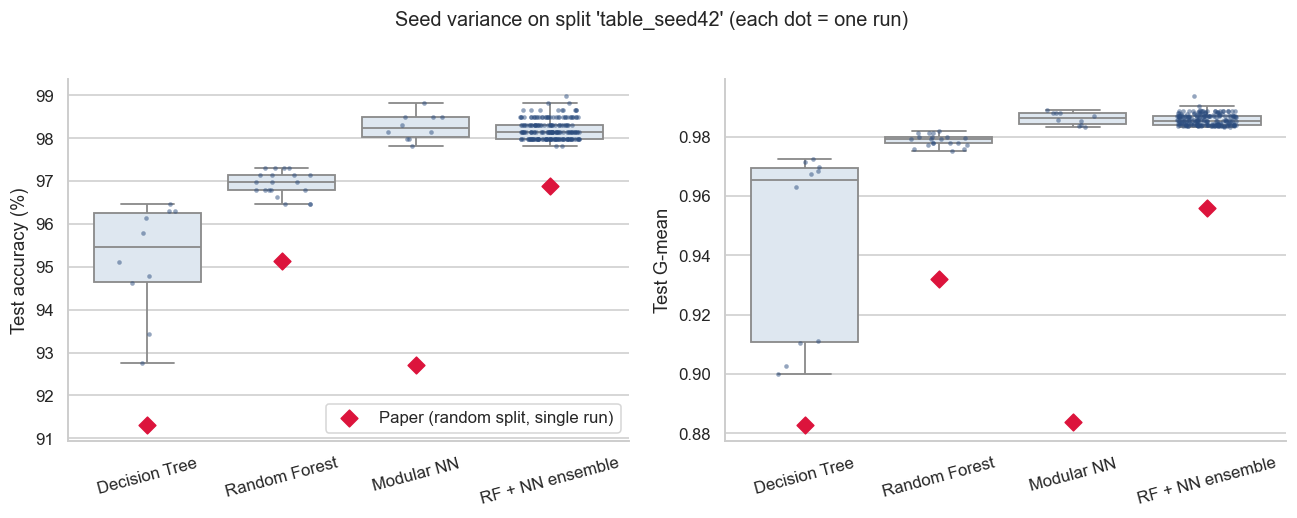

,n,acc_mean,acc_std,f1_mean,gmean_mean,gmean_std,gmean_min,gmean_max
model,,,,,,,,
Decision Tree,10,95.1684,1.2822,0.9518,0.9437,0.0326,0.8999,0.9724
Random Forest,20,96.9360,0.2870,0.9696,0.9788,0.0020,0.9751,0.9819
Modular NN,10,98.2660,0.3079,0.9827,0.9861,0.0021,0.9831,0.9890
RF + NN ensemble,200,98.2088,0.2258,0.9822,0.9858,0.0018,0.9831,0.9938


In [28]:
exp1 = load_or_run("seed_variance", run_seed_variance)

PAPER = {"Decision Tree": (91.32, 0.883), "Random Forest": (95.14, 0.932),
         "Modular NN": (92.71, 0.884), "RF + NN ensemble": (96.88, 0.956)}
src = {"Decision Tree": exp1["dt"], "Random Forest": exp1["rf"], "Modular NN": exp1["nn"], "RF + NN ensemble": exp1["ens_cross"]}
print(f"NN inputs: {NN_TAG}")
sv = pd.DataFrame([dict(model=m, acc=r["acc"], f1=r["f1"], gmean=r["gmean"]) for m, L in src.items() for r in L])
order = list(src)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (metric, ylabel, k) in zip(axes, [("acc", "Test accuracy (%)", 0), ("gmean", "Test G-mean", 1)]):
    sns.boxplot(data=sv, x="model", y=metric, order=order, ax=ax, color="#dbe7f3", fliersize=0, linewidth=1.2)
    sns.stripplot(data=sv, x="model", y=metric, order=order, ax=ax, color="#2b4c7e", size=3, alpha=.5, jitter=.22)
    for i, m in enumerate(order):
        ax.scatter(i, PAPER[m][k], marker="D", s=60, color="crimson", zorder=6, label="Paper (random split, single run)" if i == 0 else None)
    ax.set_xlabel(""); ax.set_ylabel(ylabel); ax.tick_params(axis="x", rotation=15)
axes[0].legend(loc="lower right", frameon=True)
fig.suptitle(f"Seed variance on split '{SPLIT_NAME}' (each dot = one run)", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

tbl = sv.groupby("model", sort=False).agg(n=("acc", "size"), acc_mean=("acc", "mean"), acc_std=("acc", "std"),
                                         f1_mean=("f1", "mean"), gmean_mean=("gmean", "mean"), gmean_std=("gmean", "std"),
                                         gmean_min=("gmean", "min"), gmean_max=("gmean", "max")).round(4)
display(tbl)

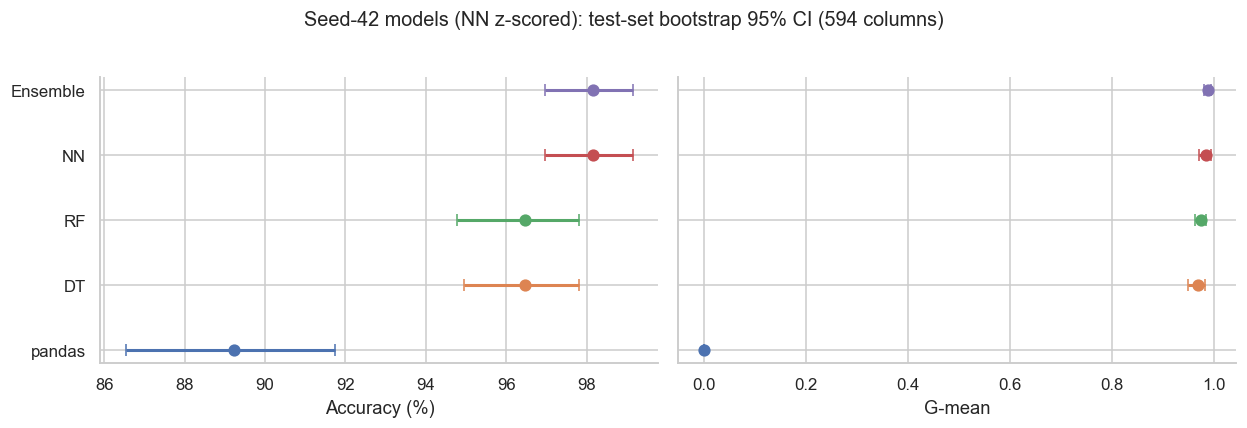

Paired bootstrap, Ensemble minus RF (seed 42): accuracy CI +0.51 .. +3.03 pts, G-mean CI +0.005 .. +0.023  (intervals containing 0 are not separable on this test set)


In [29]:
ci = exp1["bootstrap_ci"]; names = ["pandas", "DT", "RF", "NN", "Ensemble"]
pal = sns.color_palette("deep", len(names))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for ax, (metric, lab) in zip(axes, [("acc", "Accuracy (%)"), ("gmean", "G-mean")]):
    for i, n in enumerate(names):
        pt = ci[n]["point"][metric]; lo, hi = ci[n][metric]
        ax.errorbar(pt, i, xerr=[[pt - lo], [hi - pt]], fmt="o", capsize=4, color=pal[i], lw=2, ms=7)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.invert_yaxis(); ax.set_xlabel(lab)
fig.suptitle(f"Seed-42 models (NN {NN_TAG}): test-set bootstrap 95% CI ({len(x_load_split()['test']['y'])} columns)", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()
d = exp1["paired_ens_minus_rf"]
print(f"Paired bootstrap, Ensemble minus RF (seed 42): accuracy CI {d['acc'][0]:+.2f} .. {d['acc'][1]:+.2f} pts, "
      f"G-mean CI {d['gmean'][0]:+.3f} .. {d['gmean'][1]:+.3f}  (intervals containing 0 are not separable on this test set)")

## 11. How optimistic is a random split? Leakage and grouped splits
First, how often does a test column of the split selected in section 3 have a *sibling* in its training set (for a table-grouped split this should be 0% for "same table")? Then the models are re-evaluated on 5 random-stratified, 5 table-grouped (all columns of a CSV in one partition) and 5 source-grouped (all tables of a dataset together) 70/15/15 splits, with `SPLIT_MODEL_SEEDS` model seeds trained on **every** split, so the spread combines split and training variance (the table under the plot separates the two). GitTables sources are grouped by topic folder (the repository name is not recorded), so treat source-grouping as indicative.

[grouped_splits] computing ...
rebuilt (3188, 295)
LEAKAGE {'test_cols_with_train_col_from_same_table': 0.0, 'test_cols_with_train_col_from_same_source': 0.6077441077441077, 'test_cols_with_same_name_in_train': 0.563973063973064, 'n_tables_total': 400, 'test_cols_with_same_name_and_label_in_train': 0.563973063973064}
random 1 42 [2231, 478, 479] [206, 212, 30, 31] | RF g 0.96 Ens acc 98.33 g 0.99 20
random 1 0 [2231, 478, 479] [206, 212, 30, 31] | RF g 0.963 Ens acc 98.12 g 0.989 32
random 1 1 [2231, 478, 479] [206, 212, 30, 31] | RF g 0.95 Ens acc 98.33 g 0.99 43
random 2 42 [2231, 478, 479] [206, 212, 31, 30] | RF g 0.975 Ens acc 98.54 g 0.991 55
random 2 0 [2231, 478, 479] [206, 212, 31, 30] | RF g 0.965 Ens acc 98.54 g 0.991 71
random 2 1 [2231, 478, 479] [206, 212, 31, 30] | RF g 0.967 Ens acc 98.54 g 0.991 83
random 3 42 [2231, 478, 479] [206, 212, 31, 30] | RF g 0.964 Ens acc 98.75 g 0.993 106
random 3 0 [2231, 478, 479] [206, 212, 31, 30] | RF g 0.964 Ens acc 99.16 g 0.995 124


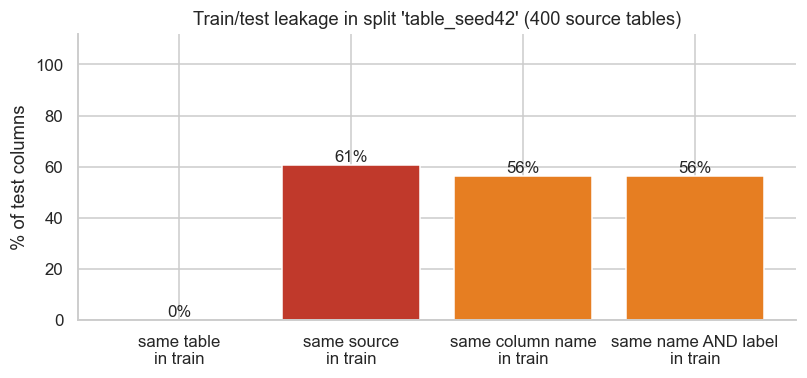

In [30]:
grp = load_or_run("grouped_splits", run_grouped_splits)
alt = load_or_run("scaling_alt", run_scaling_alt)

lk = grp["leakage"]
leak = pd.Series({"same table\nin train": lk["test_cols_with_train_col_from_same_table"],
                  "same source\nin train": lk["test_cols_with_train_col_from_same_source"],
                  "same column name\nin train": lk["test_cols_with_same_name_in_train"],
                  "same name AND label\nin train": lk["test_cols_with_same_name_and_label_in_train"]}) * 100
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bars = ax.bar(leak.index, leak.values, color=["#c0392b", "#c0392b", "#e67e22", "#e67e22"])
for b, v in zip(bars, leak.values): ax.text(b.get_x() + b.get_width() / 2, v + 1.2, f"{v:.0f}%", ha="center", fontsize=11)
ax.set_ylim(0, 112); ax.set_ylabel("% of test columns")
ax.set_title(f"Train/test leakage in split '{SPLIT_NAME}' ({lk['n_tables_total']} source tables)")
plt.tight_layout(); plt.show()

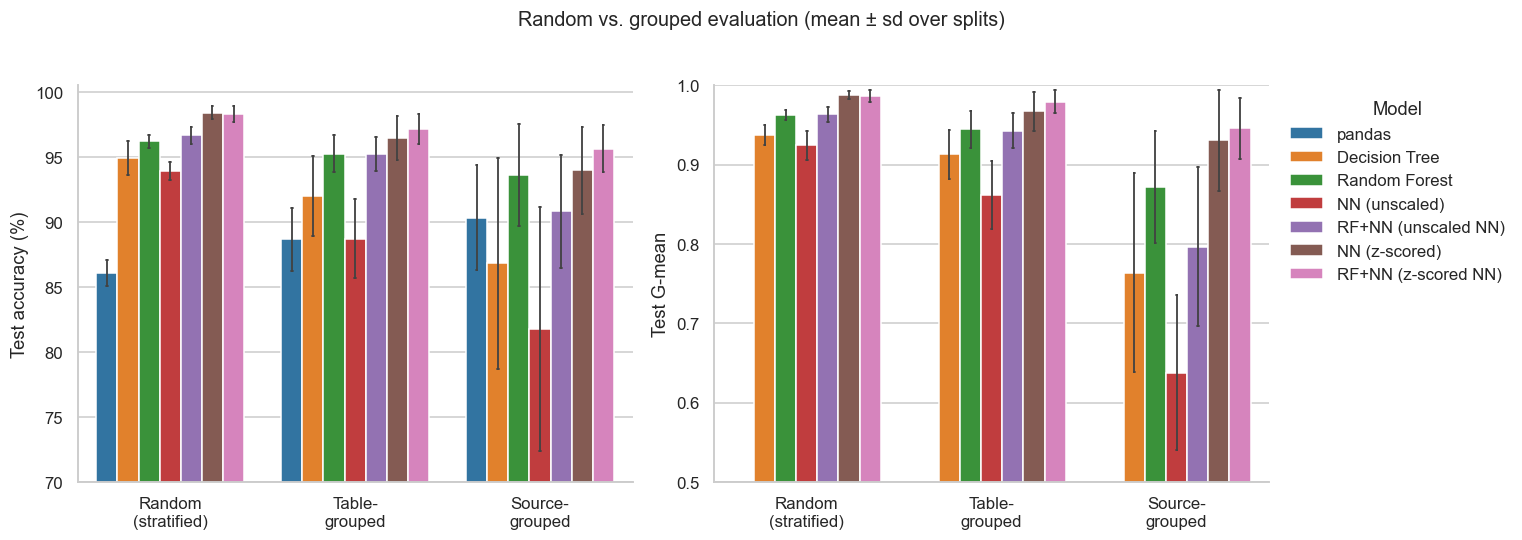

acc  acc_sd  gmean  gmean_sd
random pandas               86.096   1.001  0.000     0.000
       Decision Tree        94.934   1.307  0.937     0.013
       Random Forest        96.186   0.532  0.963     0.006
       NN (unscaled)        93.904   0.711  0.924     0.018
       RF+NN (unscaled NN)  96.674   0.648  0.964     0.010
       NN (z-scored)        98.413   0.498  0.988     0.006
       RF+NN (z-scored NN)  98.302   0.595  0.987     0.008
table  pandas               88.661   2.414  0.000     0.000
       Decision Tree        92.031   3.075  0.913     0.031
       Random Forest        95.245   1.433  0.944     0.023
       NN (unscaled)        88.699   3.044  0.862     0.043
       RF+NN (unscaled NN)  95.224   1.340  0.943     0.022
       NN (z-scored)        96.461   1.706  0.968     0.025
       RF+NN (z-scored NN)  97.157   1.178  0.979     0.014
source pandas               90.331   4.055  0.000     0.000
       Decision Tree        86.817   8.136  0.764     0.125
       Random Forest        93.615   3.900  0.872     0.071
       NN (unscaled)        81.770   9.352  0.638     0.098
       RF+NN (unscaled NN)  90.814   4.356  0.797     0.100
       NN (z-scored)        93.957   3.316  0.931     0.064
       RF+NN (z-scored NN)  95.641   1.827  0.946     0.038

pandas always has G-mean 0: it never predicts a temporal type (dates stay `object`).

G-mean variance decomposition:


between_splits_sd  within_split_seed_sd
random pandas                          0.0000                0.0000
       Decision Tree                   0.0116                0.0070
       Random Forest                   0.0042                0.0043
       NN (unscaled)                   0.0182                0.0072
       RF+NN (unscaled NN)             0.0094                0.0045
       NN (z-scored)                   0.0059                0.0008
       RF+NN (z-scored NN)             0.0075                0.0022
table  pandas                          0.0000                0.0000
       Decision Tree                   0.0324                0.0070
       Random Forest                   0.0248                0.0033
       NN (unscaled)                   0.0452                0.0096
       RF+NN (unscaled NN)             0.0236                0.0025
       NN (z-scored)                   0.0258                0.0060
       RF+NN (z-scored NN)             0.0148                0.0038
source pandas                          0.0000                0.0000
       Decision Tree                   0.1335                0.0194
       Random Forest                   0.0618                0.0292
       NN (unscaled)                   0.0973                0.0341
       RF+NN (unscaled NN)             0.1062                0.0219
       NN (z-scored)                   0.0433                0.0366
       RF+NN (z-scored NN)             0.0281                0.0250

In [31]:
NAMES = {"pandas": "pandas", "DT": "Decision Tree", "RF": "Random Forest", "NN": f"NN ({NN_TAG})", "Ens": f"RF+NN ({NN_TAG} NN)"}
rows = []
for r in grp["runs"]:
    for k, nm in NAMES.items(): rows.append(dict(split=r["kind"], seed=r["seed"], model_seed=r.get("model_seed", 42), model=nm, acc=r[k]["acc"], f1=r[k]["f1"], gmean=r[k]["gmean"]))
for r in alt["grouped_alt"]:
    for k, nm in {"NNalt": f"NN ({ALT_TAG})", "Ens_alt": f"RF+NN ({ALT_TAG} NN)"}.items():
        rows.append(dict(split=r["kind"], seed=r["seed"], model_seed=r.get("model_seed", 42), model=nm, acc=r[k]["acc"], f1=r[k]["f1"], gmean=r[k]["gmean"]))
gs = pd.DataFrame(rows)
hue_order = ["pandas", "Decision Tree", "Random Forest", "NN (unscaled)", "RF+NN (unscaled NN)", "NN (z-scored)", "RF+NN (z-scored NN)"]
hue_order = [h for h in hue_order if h in set(gs.model)]
split_order = [s for s in ["random", "table", "source"] if s in set(gs.split)]
xt = {"random": "Random\n(stratified)", "table": "Table-\ngrouped", "source": "Source-\ngrouped"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (metric, lab) in zip(axes, [("acc", "Test accuracy (%)"), ("gmean", "Test G-mean")]):
    sns.barplot(data=gs, x="split", y=metric, hue="model", order=split_order, hue_order=hue_order, errorbar="sd",
                capsize=.06, err_kws={"linewidth": 1.2}, palette=sns.color_palette("tab10")[:len(hue_order)], ax=ax)
    ax.set_xticks(range(len(split_order))); ax.set_xticklabels([xt[s] for s in split_order]); ax.set_xlabel(""); ax.set_ylabel(lab)
    ax.set_ylim(70 if metric == "acc" else 0.5, 100.5 if metric == "acc" else 1.0)
    if ax is axes[0]: ax.legend_.remove()
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, title="Model")
fig.suptitle("Random vs. grouped evaluation (mean ± sd over splits)", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

piv = gs.groupby(["split", "model"]).agg(acc=("acc", "mean"), acc_sd=("acc", "std"), gmean=("gmean", "mean"), gmean_sd=("gmean", "std")).round(3)
display(piv.reindex(pd.MultiIndex.from_product([split_order, hue_order]), fill_value=np.nan).dropna(how="all"))
print("pandas always has G-mean 0: it never predicts a temporal type (dates stay `object`).")

# Where does the spread come from? split-to-split (sd of the per-split means) vs. model seed (mean sd within a split)
per_split = gs.groupby(["split", "model", "seed"])["gmean"].agg(["mean", "std"])
decomp = per_split.groupby(["split", "model"]).agg(between_splits_sd=("mean", "std"), within_split_seed_sd=("std", "mean"))
print("\nG-mean variance decomposition:")
display(decomp.reindex(pd.MultiIndex.from_product([split_order, hue_order])).dropna(how="all").round(4))

## 12. Standardizing the NN inputs
The NN receives raw features (string lengths, character frequencies, ...) on very different scales. This compares the variant used everywhere else (`NN_TAG`) with the opposite one (`ALT_TAG`), both on the split from section 3 (10 seeds each; RF shown for reference). The grouped-split version of the same comparison is in the §11 table.

/var/folders/hg/fq57sy157xxf2tb_3b7nc79r0000gn/T/ipykernel_42973/20709157.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cmp, x="model", y=metric, order=order2, palette=pal2, ax=ax, fliersize=0, linewidth=1.1, boxprops=dict(alpha=.55))
/var/folders/hg/fq57sy157xxf2tb_3b7nc79r0000gn/T/ipykernel_42973/20709157.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cmp, x="model", y=metric, order=order2, palette=pal2, ax=ax, fliersize=0, linewidth=1.1, boxprops=dict(alpha=.55))


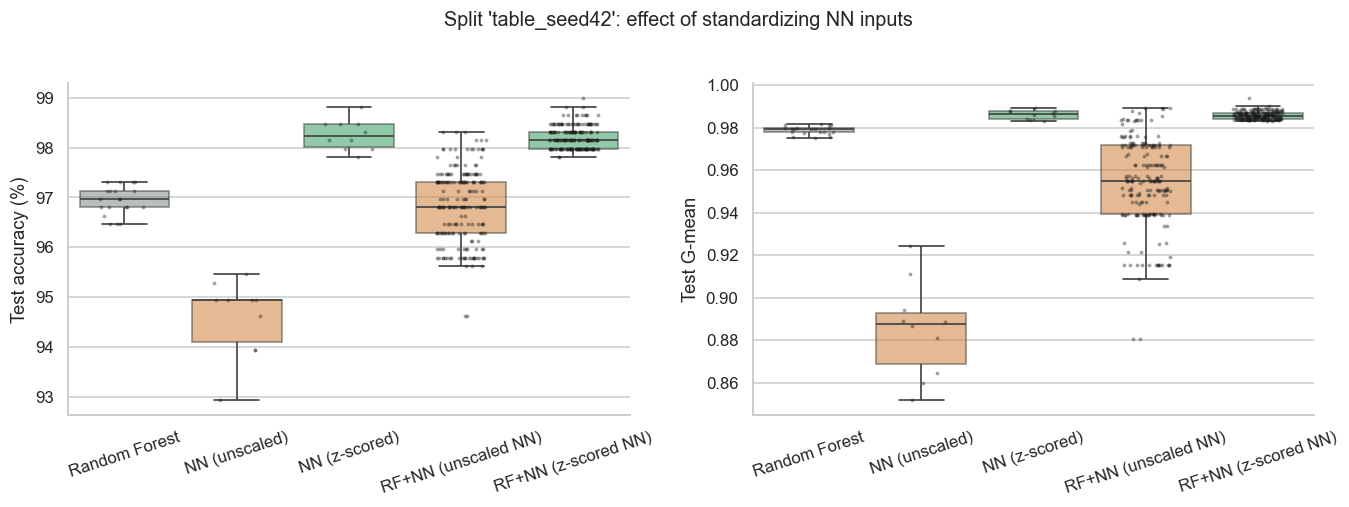

,n,acc,acc_sd,gmean,gmean_sd
model,,,,,
Random Forest,20,96.9360,0.2870,0.9788,0.0020
NN (unscaled),10,94.5960,0.7713,0.8852,0.0224
NN (z-scored),10,98.2660,0.3079,0.9861,0.0021
RF+NN (unscaled NN),200,96.8434,0.7350,0.9545,0.0205
RF+NN (z-scored NN),200,98.2088,0.2258,0.9858,0.0018


In [32]:
ps = alt["paper_split"]
rf_ref = exp1["rf"]
cmp_rows = []
variants = {NN_TAG: (exp1["nn"], exp1["ens_cross"]), ALT_TAG: (ps["nn"], ps["ens_cross"])}
for nm, L in [("Random Forest", rf_ref), ("NN (unscaled)", variants["unscaled"][0]), ("NN (z-scored)", variants["z-scored"][0]),
              ("RF+NN (unscaled NN)", variants["unscaled"][1]), ("RF+NN (z-scored NN)", variants["z-scored"][1])]:
    for r in L: cmp_rows.append(dict(model=nm, acc=r["acc"], gmean=r["gmean"]))
cmp = pd.DataFrame(cmp_rows); order2 = list(dict.fromkeys(cmp.model))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
pal2 = ["#7f8c8d", "#e67e22", "#27ae60", "#e67e22", "#27ae60"]
for ax, (metric, lab) in zip(axes, [("acc", "Test accuracy (%)"), ("gmean", "Test G-mean")]):
    sns.boxplot(data=cmp, x="model", y=metric, order=order2, palette=pal2, ax=ax, fliersize=0, linewidth=1.1, boxprops=dict(alpha=.55))
    sns.stripplot(data=cmp, x="model", y=metric, order=order2, color="k", size=2.5, alpha=.4, ax=ax, jitter=.22)
    ax.set_xlabel(""); ax.set_ylabel(lab); ax.tick_params(axis="x", rotation=18)
fig.suptitle(f"Split '{SPLIT_NAME}': effect of standardizing NN inputs", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()
display(cmp.groupby("model", sort=False).agg(n=("acc", "size"), acc=("acc", "mean"), acc_sd=("acc", "std"), gmean=("gmean", "mean"), gmean_sd=("gmean", "std")).round(4))

## 13. Which feature groups matter?
Random Forest on statistics only / embeddings only / both (5 seeds), and the NN (`NN_TAG` inputs) with one input group zeroed (3 seeds). The heat-map shows per-class recall. **Caveat:** BOOLEAN and TIME labels come from value regexes, so statistics alone separate them almost perfectly; the informative case is VARCHAR vs. NUMBER (identifier-like digits), where column names help.

[ablations] computing ...
RF stats_only
RF emb_only
RF combined
NN stats_only 42 26
NN stats_only 0 32
NN stats_only 1 41
NN emb_only 42 52
NN emb_only 0 61
NN emb_only 1 69
rebuilt rows with split: 3183 of 3188
PCA 5 79
PCA 10 86
PCA 25 94
PCA 50 103
PCA 100 113
PCA None 134
[ablations] done in 134s -> results/table_seed42_lr0.005_bs1024_scaledTrue/ablations.json


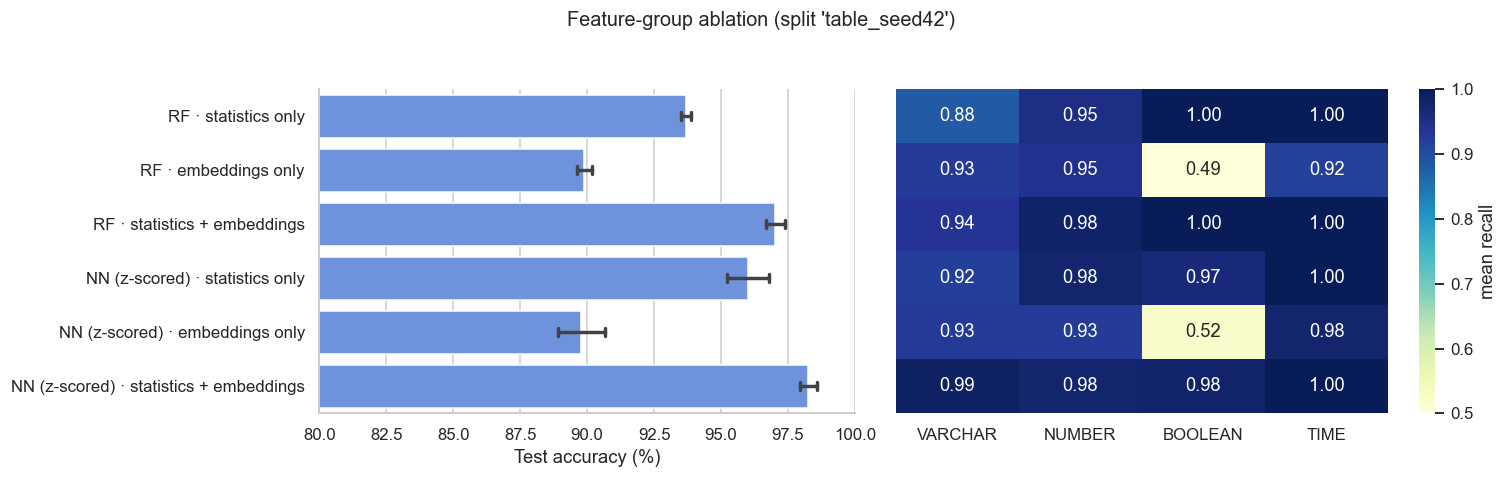

,n,acc,f1,gmean
label,,,,
RF · statistics only,5,93.7037,0.9381,0.9572
RF · embeddings only,5,89.8990,0.8940,0.7917
RF · statistics + embeddings,5,97.0370,0.9707,0.9794
NN (z-scored) · statistics only,3,96.0157,0.9602,0.9657
NN (z-scored) · embeddings only,3,89.7868,0.8942,0.8145
NN (z-scored) · statistics + embeddings,10,98.2660,0.9827,0.9861


In [33]:
ab = run_ab = load_or_run("ablations", run_ablations)
fa = pd.DataFrame(ab["feature_ablation"])
NN_LAB = f"NN ({NN_TAG})"
fa["model"] = fa.model.replace({"NN": NN_LAB})
nn_full = pd.DataFrame(exp1["nn"]).assign(model=NN_LAB, cfg="combined")
fa = pd.concat([fa[["model", "cfg", "seed", "acc", "f1", "gmean", "rec"]], nn_full[["model", "cfg", "seed", "acc", "f1", "gmean", "rec"]]], ignore_index=True)
cfg_names = {"stats_only": "statistics only", "emb_only": "embeddings only", "combined": "statistics + embeddings"}
fa["label"] = fa.model + " · " + fa.cfg.map(cfg_names)
lab_order = [f"{m} · {c}" for m in ["RF", NN_LAB] for c in cfg_names.values()]
lab_order = [l for l in lab_order if l in set(fa.label)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.15]})
sns.barplot(data=fa, y="label", x="acc", order=lab_order, errorbar="sd", color="#5b8def", ax=axes[0], capsize=.15)
axes[0].set_xlim(80, 100); axes[0].set_xlabel("Test accuracy (%)"); axes[0].set_ylabel("")
rec = fa.groupby("label")["rec"].apply(lambda s: np.mean(np.vstack(s.tolist()), axis=0)).reindex(lab_order)
rm = pd.DataFrame(np.vstack(rec.values), index=lab_order, columns=["VARCHAR", "NUMBER", "BOOLEAN", "TIME"])
sns.heatmap(rm, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0.5, vmax=1.0, cbar_kws={"label": "mean recall"}, ax=axes[1])
axes[1].set_ylabel(""); axes[1].set_yticklabels([])
fig.suptitle(f"Feature-group ablation (split '{SPLIT_NAME}')", y=1.03, fontsize=13)
plt.tight_layout(); plt.show()
display(fa.groupby("label").agg(n=("acc", "size"), acc=("acc", "mean"), f1=("f1", "mean"), gmean=("gmean", "mean")).reindex(lab_order).round(4))

## 14. Sensitivity to the number of PCA components
The pipeline uses **25 components per token** throughout (fixed in 04_data_preparation.ipynb). This section checks how much that choice matters: Random Forest over 5 seeds for each size, with validation and test metrics. It is a sensitivity check, not a selection step; the results elsewhere in this notebook all use 25. The 300-dimensional raw-embedding variant (8 × 300 = 2,400 features) is shown for reference from the earlier ablation.

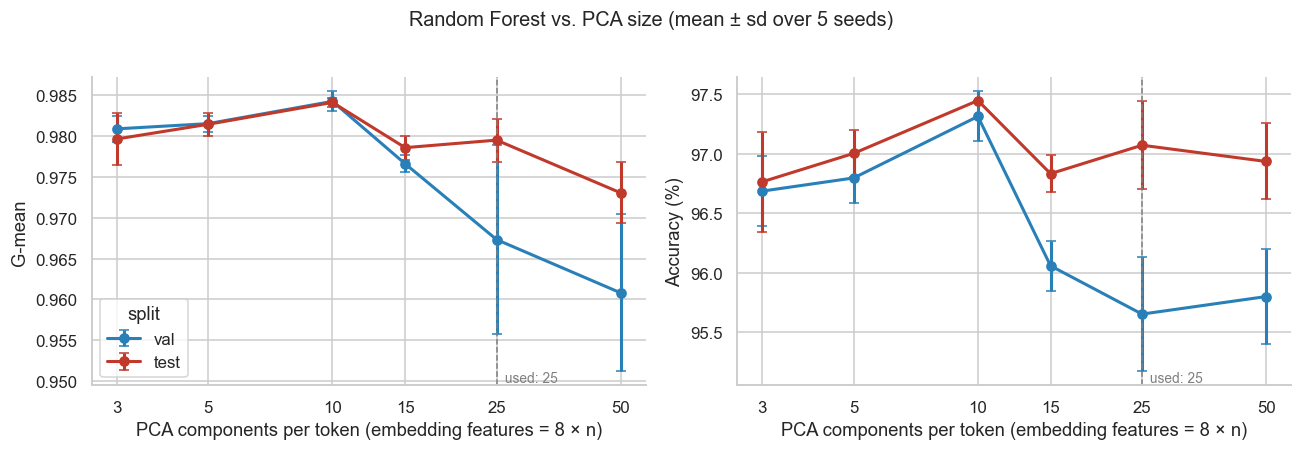

Used: 25 components -> val G-mean 0.9673, test G-mean 0.9795
Best on validation: 10 components -> val G-mean 0.9842 (difference +0.0169; single split, RF only)
Reference (test only): raw 300-d embeddings -> acc 94.38, G-mean 0.897 (n=3)


val_acc           val_g         test_acc          test_g        
       mean     std    mean     std     mean     std    mean     std
nc                                                                  
3   96.6851  0.2912  0.9809  0.0016  96.7632  0.4173  0.9796  0.0031
5   96.7956  0.2100  0.9815  0.0010  97.0017  0.1942  0.9814  0.0014
10  97.3112  0.2100  0.9842  0.0012  97.4446  0.0000  0.9841  0.0005
15  96.0589  0.2100  0.9766  0.0010  96.8313  0.1524  0.9786  0.0015
25  95.6538  0.4802  0.9673  0.0115  97.0698  0.3693  0.9795  0.0026
50  95.8011  0.3993  0.9608  0.0096  96.9336  0.3187  0.9730  0.0037

In [36]:
pv = pd.DataFrame([dict(nc=r["nc"], seed=r["seed"], val_acc=r["val"]["acc"], val_g=r["val"]["gmean"],
                        test_acc=r["test"]["acc"], test_g=r["test"]["gmean"]) for r in alt["pca_val"]])
g = pv.drop(columns="seed").groupby("nc").agg(["mean", "std"]); ncs = list(g.index)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (m, lab) in zip(axes, [("g", "G-mean"), ("acc", "Accuracy (%)")]):
    for split, col in [("val", "#2980b9"), ("test", "#c0392b")]:
        mu, sd = g[(f"{split}_{m}", "mean")], g[(f"{split}_{m}", "std")]
        ax.errorbar(ncs, mu, yerr=sd, marker="o", capsize=3, color=col, label=split, lw=2)
    ax.axvline(25, ls="--", color="gray", lw=1); ax.text(25.6, ax.get_ylim()[0], " used: 25", color="gray", va="bottom", fontsize=9)
    ax.set_xlabel("PCA components per token (embedding features = 8 × n)"); ax.set_ylabel(lab); ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(ncs); ax.set_xticklabels(ncs)
axes[0].legend(title="split"); fig.suptitle("Random Forest vs. PCA size (mean ± sd over 5 seeds)", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()
best_val = g[("val_g", "mean")].idxmax(); used = g.loc[25]
print(f"Used: 25 components -> val G-mean {used[('val_g','mean')]:.4f}, test G-mean {used[('test_g','mean')]:.4f}")
print(f"Best on validation: {best_val} components -> val G-mean {g.loc[best_val, ('val_g','mean')]:.4f} "
      f"(difference {g.loc[best_val, ('val_g','mean')] - used[('val_g','mean')]:+.4f}; single split, RF only)")
raw = pd.DataFrame(ab["pca_ablation"]); raw = raw[raw.nc.astype(str).isin(["raw300"])]
if len(raw): print(f"Reference (test only): raw 300-d embeddings -> acc {raw.acc.mean():.2f}, G-mean {raw.gmean.mean():.3f} (n={len(raw)})")
display(g.round(4))

## 15. Headline result: performance on unseen tables and unseen sources
**These are the numbers to report.** Every model is evaluated on 5 table-grouped splits (no test column shares a CSV with training) and 5 source-grouped splits (no test column shares a dataset with training), with `SPLIT_MODEL_SEEDS` model seeds per split. Each cell is mean ± sd over all split × seed runs; *between-split sd* is the sd of the per-split means, i.e. how much the score moves when a different set of tables is held out. The single-split results in §5–§8 and §10 sit inside these ranges and only measure training noise.

runs  splits  accuracy (%)             F1  \
unseen tables  pandas                 15       5  88.66 ± 2.41  0.860 ± 0.031   
               Decision Tree          15       5  92.03 ± 3.08  0.920 ± 0.031   
               Random Forest          15       5  95.25 ± 1.43  0.953 ± 0.014   
               NN (z-scored)          15       5  96.46 ± 1.71  0.966 ± 0.017   
               RF+NN (z-scored NN)    15       5  97.16 ± 1.18  0.972 ± 0.012   
unseen sources pandas                 15       5  90.33 ± 4.06  0.889 ± 0.049   
               Decision Tree          15       5  86.82 ± 8.14  0.867 ± 0.078   
               Random Forest          15       5  93.61 ± 3.90  0.936 ± 0.039   
               NN (z-scored)          15       5  93.96 ± 3.32  0.942 ± 0.031   
               RF+NN (z-scored NN)    15       5  95.64 ± 1.83  0.957 ± 0.018   

                                           G-mean  G-mean between-split sd  
unseen tables  pandas               0.000 ± 0.000                    0.000  
               Decision Tree        0.913 ± 0.031                    0.032  
               Random Forest        0.944 ± 0.023                    0.025  
               NN (z-scored)        0.968 ± 0.025                    0.026  
               RF+NN (z-scored NN)  0.979 ± 0.014                    0.015  
unseen sources pandas               0.000 ± 0.000                    0.000  
               Decision Tree        0.764 ± 0.125                    0.134  
               Random Forest        0.872 ± 0.071                    0.062  
               NN (z-scored)        0.931 ± 0.064                    0.043  
               RF+NN (z-scored NN)  0.946 ± 0.038                    0.028

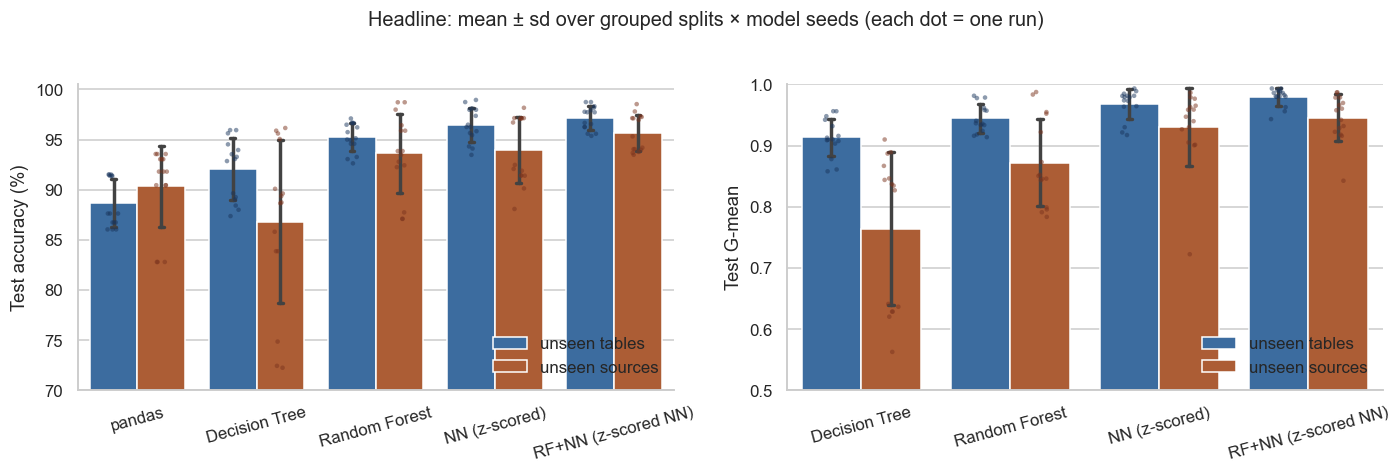

pandas G-mean is 0 by construction (never predicts a temporal type); compare it on accuracy / F1.


In [35]:
HEAD_MODELS = ["pandas", "Decision Tree", "Random Forest", f"NN ({NN_TAG})", f"RF+NN ({NN_TAG} NN)"]
H = gs[gs.split.isin(["table", "source"]) & gs.model.isin(HEAD_MODELS)]

def pm(s, d=3):   # "mean ± sd"
    return f"{s.mean():.{d}f} ± {s.std():.{d}f}"

head = (H.groupby(["split", "model"])[["seed", "acc", "f1", "gmean"]]
          .apply(lambda g: pd.Series({
              "runs": len(g),
              "splits": g.seed.nunique(),
              "accuracy (%)": pm(g.acc, 2),
              "F1": pm(g.f1),
              "G-mean": pm(g.gmean),
              "G-mean between-split sd": round(g.groupby("seed").gmean.mean().std(), 3),
          }))
          .reindex(pd.MultiIndex.from_product([["table", "source"], HEAD_MODELS])).dropna(how="all"))
head.index = head.index.set_levels(["unseen sources" if s == "source" else "unseen tables" for s in head.index.levels[0]], level=0)
display(head)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
for ax, (metric, lab, lo) in zip(axes, [("acc", "Test accuracy (%)", 70), ("gmean", "Test G-mean", 0.5)]):
    hh = H[H.model != "pandas"] if metric == "gmean" else H
    order = [m for m in HEAD_MODELS if m in set(hh.model)]
    sns.barplot(data=hh, x="model", y=metric, hue="split", order=order, hue_order=["table", "source"], errorbar="sd",
                capsize=.08, palette=["#2b6cb0", "#c05621"], ax=ax)
    sns.stripplot(data=hh, x="model", y=metric, hue="split", order=order, hue_order=["table", "source"], dodge=True,
                  palette=["#1a365d", "#7b341e"], size=3, alpha=.5, legend=False, ax=ax)
    ax.set_ylim(lo, 100.5 if metric == "acc" else 1.0); ax.set_xlabel(""); ax.set_ylabel(lab); ax.tick_params(axis="x", rotation=15)
    h, l = ax.get_legend_handles_labels(); ax.legend(h, ["unseen tables", "unseen sources"], frameon=False, loc="lower right")
fig.suptitle("Headline: mean ± sd over grouped splits × model seeds (each dot = one run)", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()
print("pandas G-mean is 0 by construction (never predicts a temporal type); compare it on accuracy / F1.")

## Reading the results
* **Report the cross-split numbers (§15).** Retraining with a different seed moves G-mean in the third decimal, but holding out a different set of tables moves it 3–5× more (§11 variance decomposition). A single split, including the one in section 3, can land anywhere in that range.
* **Random splits are optimistic** (§11): a column-level random split puts siblings from the same table in train and test. Table-grouping removes that; source-grouping also removes near-duplicate tables from the same dataset and is the closest to deploying on a new database. Column names still repeat across tables (`created_at`, ...), so some of the remaining performance comes from familiar names.
* **Input scaling matters for the NN** (§12, §11): compare the `NN_TAG` and `ALT_TAG` rows.
* **Ensemble vs. single models:** check whether the RF+NN gain over the NN exceeds the between-split sd in §15; on a single split it is usually inside the noise. Its more useful property is a smaller spread under source-grouping.
* **Statistics and name embeddings are complementary** (§13). BOOLEAN/TIME are nearly solved by statistics alone (their labels come from value regexes); embeddings mainly rescue VARCHAR-vs-NUMBER identifiers.
* **PCA size** (§14): 25 components are used everywhere. The sweep shows how sensitive the RF is to that choice on one split; report it as a sensitivity check, not as tuning.